# Trabajo Práctico Especial: Stack Overflow Developer Survey 2025

**Fundamentos de la Ciencia de Datos (UNICEN, 2026). Grupo 5:** Landolfi, Mateo Nicolás · Bottini, Yaco · Barletta, Ian Franco Pehuen.

La notebook sigue la misma organización que el informe:

1. Análisis exploratorio inicial
2. Limpieza de la base de datos
3. Planteo y validación de las hipótesis propias (A. univariada, B. bivariada, C. multivariada)
4. Validación de las hipótesis propuestas por la cátedra (a, b y c)

La celda siguiente importa las librerías y carga los datos (`results.csv.gz`, incluido en el repositorio).

In [1]:
!pip install wget -q
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from os import path

# El archivo results.csv.gz viene incluido en el repositorio.
# Si no está (por ejemplo, en Colab), se descarga el CSV original.
if path.exists("results.csv.gz"):
    df = pd.read_csv("results.csv.gz", low_memory=False)
else:
    from wget import download
    if not path.exists("results.csv"):
        download("https://media.githubusercontent.com/media/StackExchange/Survey/6ae2209cd35a55e92739ba82f7887fb86807a069/packages/archive/2025/results.csv")
    df = pd.read_csv("results.csv", low_memory=False)

# 1. Análisis Exploratorio Inicial: ¿de dónde vienen los datos?

## 1.1 Fuente de los datos y forma de recolección
El conjunto de datos utilizado en este trabajo corresponde a la Stack Overflow Developer Survey 2025. La misma fue diseñada y llevada a cabo por Stack Overflow, una plataforma tecnológica tipo foro sobre programación, con el objetivo de conocer las características, experiencias, preferencias y opiniones de las personas vinculadas al desarrollo de software y otras actividades relacionadas con la tecnología. La encuesta recibió más de 49.000 respuestas de 177 países diferentes, contando con 62 preguntas en total.

La convocatoria se difundió mediante:

* Mensajes y anuncios dentro de la plataforma
* Publicaciones en su blog
* Correos electrónicos y boletines
* Anuncios publicitarios y redes sociales

Por eso, aunque la encuesta tiene alcance internacional, la muestra no se seleccionó de forma aleatoria: la participación fue voluntaria. Es posible que haya un sesgo de selección, porque las personas más involucradas con Stack Overflow son las que más probablemente vieron la invitación y participaron. Entonces, los resultados describen principalmente a este grupo de personas, no necesariamente a toda la población mundial de desarrolladores.

## 1.2 Estructura del conjunto de datos
El conjunto de datos está organizado en formato tabular: cada fila representa una respuesta individual y cada columna corresponde a una variable asociada a la información relevada por la encuesta. Contiene 49.191 registros y 172 atributos. La cantidad y diversidad de columnas se explica por la amplitud temática de la encuesta y por la forma en que se representan las respuestas. Algunas preguntas generan una única variable, mientras que otras, especialmente las de selección múltiple o las que permiten especificar respuestas adicionales, pueden estar representadas mediante varias columnas.
Es importante remarcar que el dataset tiene 172 columnas, pero en realidad son 62 las preguntas totales de la encuesta.

En la celda siguiente se muestran las dimensiones, los nombres y los tipos de las columnas y las primeras filas.

In [2]:
print("Dimensiones:", df.shape)

print("\nNombres de las columnas:")
for columna in df.columns:
    print(columna)

print("\nTipos de datos:")
display(df.dtypes.value_counts())

print("\nPrimeras filas:")
display(df.head())

df.info(verbose=True, show_counts=True)

Dimensiones: (49191, 172)

Nombres de las columnas:
ResponseId
MainBranch
Age
EdLevel
Employment
EmploymentAddl
WorkExp
LearnCodeChoose
LearnCode
LearnCodeAI
AILearnHow
YearsCode
DevType
OrgSize
ICorPM
RemoteWork
PurchaseInfluence
TechEndorseIntro
TechEndorse_1
TechEndorse_2
TechEndorse_3
TechEndorse_4
TechEndorse_5
TechEndorse_6
TechEndorse_7
TechEndorse_8
TechEndorse_9
TechEndorse_13
TechEndorse_13_TEXT
TechOppose_1
TechOppose_2
TechOppose_3
TechOppose_5
TechOppose_7
TechOppose_9
TechOppose_11
TechOppose_13
TechOppose_16
TechOppose_15
TechOppose_15_TEXT
Industry
JobSatPoints_1
JobSatPoints_2
JobSatPoints_3
JobSatPoints_4
JobSatPoints_5
JobSatPoints_6
JobSatPoints_7
JobSatPoints_8
JobSatPoints_9
JobSatPoints_10
JobSatPoints_11
JobSatPoints_13
JobSatPoints_14
JobSatPoints_15
JobSatPoints_16
JobSatPoints_15_TEXT
AIThreat
NewRole
ToolCountWork
ToolCountPersonal
Country
Currency
CompTotal
LanguageChoice
LanguageHaveWorkedWith
LanguageWantToWorkWith
LanguageAdmired
LanguagesHaveEntry
Langu

str        119
float64     52
int64        1
Name: count, dtype: int64


Primeras filas:


,ResponseId,MainBranch,Age,EdLevel,Employment,EmploymentAddl,WorkExp,LearnCodeChoose,LearnCode,LearnCodeAI,...,AIAgentOrchestration,AIAgentOrchWrite,AIAgentObserveSecure,AIAgentObsWrite,AIAgentExternal,AIAgentExtWrite,AIHuman,AIOpen,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,25-34 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Employed,"Caring for dependents (children, elderly, etc.)",8.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,Vertex AI,NaN,NaN,NaN,ChatGPT,NaN,When I don’t trust AI’s answers,"Troubleshooting, profiling, debugging",61256.0,10.0
1,2,I am a developer by profession,25-34 years old,"Associate degree (A.A., A.S., etc.)",Employed,NaN,2.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers;When I want to...,All skills. AI is a flop.,104413.0,9.0
2,3,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Independent contractor, freelancer, or self-em...",None of the above,10.0,"Yes, I am not new to coding but am learning ne...",Online Courses or Certification (includes all ...,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code;GitHub Copilot;Google Gemini,NaN,When I don’t trust AI’s answers;When I want to...,"Understand how things actually work, problem s...",53061.0,8.0
3,4,I am a developer by profession,35-44 years old,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Employed,None of the above,4.0,"Yes, I am not new to coding but am learning ne...","Other online resources (e.g. standard search, ...","Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,ChatGPT;Claude Code,NaN,When I don’t trust AI’s answers;When I want to...,NaN,36197.0,6.0
4,5,I am a developer by profession,35-44 years old,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)","Independent contractor, freelancer, or self-em...","Caring for dependents (children, elderly, etc.)",21.0,"No, I am not new to coding and did not learn n...",NaN,"Yes, I learned how to use AI-enabled tools for...",...,NaN,NaN,NaN,NaN,NaN,NaN,When I don’t trust AI’s answers,"critical thinking, the skill to define the tas...",60000.0,7.0


<class 'pandas.DataFrame'>
RangeIndex: 49191 entries, 0 to 49190
Data columns (total 172 columns):
 #    Column                                    Non-Null Count  Dtype  
---   ------                                    --------------  -----  
 0    ResponseId                                49191 non-null  int64  
 1    MainBranch                                49191 non-null  str    
 2    Age                                       49191 non-null  str    
 3    EdLevel                                   48149 non-null  str    
 4    Employment                                48339 non-null  str    
 5    EmploymentAddl                            44875 non-null  str    
 6    WorkExp                                   42893 non-null  float64
 7    LearnCodeChoose                           46858 non-null  str    
 8    LearnCode                                 33556 non-null  str    
 9    LearnCodeAI                               45201 non-null  str    
 10   AILearnHow                     

## 1.3 Caracterización de Atributos y Granularidad
Para evitar la dispersión en 172 columnas, primero identificamos las variables que utilizaremos en las hipótesis (demográficas, laborales, económicas, de satisfacción y de IA):
- **Granularidad:** Cada fila es un microdato individual representativo de una persona encuestada (`ResponseId`).
- **Cualitativas Nominales:** `Country` (país de residencia), `RemoteWork` (modalidad de trabajo), `LearnCodeAI` (si aprendió herramientas de IA en el último año) y `NewRole` (consideración de un cambio de carrera).
- **Cualitativas Ordinales:** `Age` (rangos etarios), `EdLevel` (máximo nivel educativo formal alcanzado), `AIAcc` (confianza en la precisión de la IA), `JobSat` (satisfacción general, de 0 a 10) y `JobSatPoints_*` (ranking de los aspectos del trabajo, de 1 a 15).
- **Cuantitativas Discretas:** `WorkExp` (años de experiencia laboral).
- **Cuantitativas Continuas:** `ConvertedCompYearly` (compensación anual total convertida a USD).

**Descripción de los atributos**

El conjunto de datos abarca diferentes aspectos del perfil de los participantes, su experiencia profesional, las tecnologías que utilizan, sus condiciones laborales y sus percepciones sobre la inteligencia artificial. Para facilitar su interpretación, las variables se agrupan según la temática a la que pertenecen.

### 1.3.1 Identificación, perfil y experiencia profesional

| Atributo | Descripción |
|---|---|
| `ResponseId` | Identificador de la respuesta dentro de la encuesta. |
| `MainBranch` | Situación o perfil actual del participante respecto de la programación. |
| `Age` | Edad del participante. |
| `EdLevel` | Nivel más alto de educación formal completado. |
| `Employment` | Situación laboral actual del participante. |
| `EmploymentAddl` | Actividades laborales adicionales que realiza actualmente. |
| `WorkExp` | Años de experiencia laboral profesional, redondeados al entero más cercano. La pregunta indica que, si la respuesta es cero, debe dejarse el campo vacío. |
| `LearnCodeChoose` | Indica si el participante comenzó a aprender programación o una nueva habilidad o lenguaje durante el último año. |
| `LearnCode` | Medios o métodos mediante los cuales aprendió a programar durante el último año. Admite varias respuestas. |
| `LearnCodeAI` | Indica si dedicó tiempo durante el último año a aprender programación para IA o herramientas con IA, por cuenta propia o en el trabajo. |
| `AILearnHow` | Métodos mediante los cuales aprendió a programar para IA durante el último año. |
| `YearsCode` | Años totales de experiencia programando, incluida la adquirida durante la educación. |
| `DevType` | Tipo de trabajo actual del participante o el que ocupó durante más tiempo en el último año. |
| `OrgSize` | Cantidad aproximada de personas empleadas por la organización principal. |
| `ICorPM` | Indica si el participante es colaborador individual (*individual contributor*) o gerente de personas (*people manager*). |
| `RemoteWork` | Modalidad de trabajo del participante, por ejemplo, presencial, híbrida o remota. |

Es importante distinguir `WorkExp` de `YearsCode`: la primera variable representa la experiencia laboral profesional, mientras que la segunda incluye también los años programando antes de incorporarse al mercado laboral.

### 1.3.2 Selección y evaluación de tecnologías

| Atributo | Descripción |
|---|---|
| `PurchaseInfluence` | Influencia del participante en la compra de tecnologías dentro de su organización o actividad profesional. |
| `TechEndorseIntro` | Contexto en el que el participante evalúa tecnologías antes de ordenar los factores que influyen en su elección. |
| `TechEndorse_1` | Posición asignada a la integración de IA o capacidades de agentes de IA como factor atractivo de una tecnología. |
| `TechEndorse_2` | Posición asignada a la facilidad de uso de la API. |
| `TechEndorse_3` | Posición asignada a la robustez y completitud de la API. |
| `TechEndorse_4` | Posición asignada a la posibilidad de personalizar y mantener la base de código. |
| `TechEndorse_5` | Posición asignada a la reputación de calidad de la tecnología. |
| `TechEndorse_6` | Posición asignada a la vinculación con un proyecto de código abierto. |
| `TechEndorse_7` | Posición asignada a la marca y su imagen pública. |
| `TechEndorse_8` | Posición asignada a la confiabilidad y baja latencia. |
| `TechEndorse_9` | Posición asignada a que los costos sean manejables. |
| `TechEndorse_13` | Posición asignada a la opción «Otro» entre los factores atractivos. |
| `TechEndorse_13_TEXT` | Texto libre con otro factor especificado por el participante. |
| `TechOppose_1` | Posición asignada a la falta de IA o de agentes de IA como motivo para rechazar una tecnología. |
| `TechOppose_2` | Posición asignada a la mala usabilidad. |
| `TechOppose_3` | Posición asignada a la falta de una API o a una API deficiente. |
| `TechOppose_5` | Posición asignada a la ineficiencia o al tiempo excesivo requerido. |
| `TechOppose_7` | Posición asignada a los precios prohibitivos. |
| `TechOppose_9` | Posición asignada a las preocupaciones de seguridad o privacidad. |
| `TechOppose_11` | Posición asignada a la existencia de alternativas mejores. |
| `TechOppose_13` | Posición asignada a que la tecnología o sus características estén obsoletas. |
| `TechOppose_16` | Posición asignada a las preocupaciones éticas. |
| `TechOppose_15` | Posición asignada a la opción «Otro» entre los motivos de rechazo. |
| `TechOppose_15_TEXT` | Texto libre con otro motivo de rechazo especificado por el participante. |

Las columnas numeradas de este grupo corresponden a preguntas de ordenamiento. Cada valor es la posición que la persona le asignó a ese factor, donde 1 es el más importante.

### 1.3.3 Industria, satisfacción laboral y cambio profesional

| Atributo | Descripción |
|---|---|
| `Industry` | Industria en la que trabaja el participante. |
| `JobSatPoints_1` | Posición asignada al control sobre la calidad de los proyectos como factor de satisfacción laboral. |
| `JobSatPoints_2` | Posición asignada a la autonomía y la confianza para gestionar las propias tareas. |
| `JobSatPoints_3` | Posición asignada a la colaboración y el apoyo del equipo. |
| `JobSatPoints_4` | Posición asignada a contar con mentores expertos. |
| `JobSatPoints_5` | Posición asignada a las oportunidades de orientar y liderar compañeros con menos experiencia. |
| `JobSatPoints_6` | Posición asignada al desarrollo de conocimientos especializados. |
| `JobSatPoints_7` | Posición asignada a resolver problemas del mundo real. |
| `JobSatPoints_8` | Posición asignada a la estabilidad laboral y al crecimiento profesional dentro de una organización. |
| `JobSatPoints_9` | Posición asignada a la innovación mediante problemas complejos y desafiantes. |
| `JobSatPoints_10` | Posición asignada al trabajo con nuevas tecnologías y herramientas. |
| `JobSatPoints_11` | Posición asignada a una remuneración y beneficios competitivos. |
| `JobSatPoints_13` | Posición asignada al reconocimiento recibido de los compañeros. |
| `JobSatPoints_14` | Posición asignada al reconocimiento recibido de los responsables o líderes. |
| `JobSatPoints_15` | Posición asignada a la opción «Otro» como factor de satisfacción laboral. |
| `JobSatPoints_16` | Posición asignada a tener una buena relación con el gerente. |
| `JobSatPoints_15_TEXT` | Texto libre con otro factor de satisfacción laboral. |
| `NewRole` | Indica si el participante consideró cambiar de carrera o pasó a un nuevo puesto durante el último año. |
| `JobSat` | Nivel de satisfacción del participante con su puesto profesional actual. |

Las variables `JobSatPoints_*` representan factores de satisfacción ordenados por importancia, mientras que `JobSat` expresa la satisfacción laboral general. Esta distinción será relevante para evaluar la hipótesis sobre la relación entre satisfacción laboral y consideración de cambiar de puesto o carrera.

### 1.3.4 Herramientas de trabajo y remuneración

| Atributo | Descripción |
|---|---|
| `ToolCountWork` | Cantidad de aplicaciones o plataformas de software utilizadas regularmente en el trabajo principal durante el último año, excluyendo sistemas operativos y navegadores. |
| `ToolCountPersonal` | Cantidad de aplicaciones o plataformas utilizadas regularmente para proyectos personales u otros trabajos propios, excluyendo sistemas operativos y navegadores. |
| `Country` | País en el que reside el participante. |
| `Currency` | Moneda utilizada habitualmente o en la que resulta más cómodo estimar la remuneración. |
| `CompTotal` | Remuneración anual total declarada en la moneda del participante, incluidos salario, bonificaciones y beneficios, antes de impuestos y deducciones. |
| `ConvertedCompYearly` | Remuneración anual convertida a una moneda común para facilitar las comparaciones internacionales. |

`CompTotal` y `ConvertedCompYearly` no deben tratarse como medidas necesariamente equivalentes. Para comparar remuneraciones con el salario mínimo argentino será necesario verificar la moneda, la unidad temporal y los criterios de conversión aplicados.

### 1.3.5 Lenguajes de programación

| Atributo | Descripción |
|---|---|
| `LanguageChoice` | Indica si el participante trabajó con lenguajes de programación, scripting o marcado durante el último año, o planea utilizarlos el siguiente. |
| `LanguageHaveWorkedWith` | Lenguajes con los que trabajó de forma sustancial durante el último año. |
| `LanguageWantToWorkWith` | Lenguajes con los que desea trabajar durante el próximo año. |
| `LanguageAdmired` | Lenguajes con los que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `LanguagesHaveEntry` | Lenguajes utilizados que no aparecían en las opciones predefinidas y fueron especificados manualmente. |
| `LanguagesWantEntry` | Lenguajes que desea utilizar el próximo año y que no figuraban en las opciones predefinidas. |

### 1.3.6 Bases de datos

| Atributo | Descripción |
|---|---|
| `DatabaseChoice` | Indica si el participante trabajó con entornos de bases de datos durante el último año o planea hacerlo el siguiente. |
| `DatabaseHaveWorkedWith` | Entornos de bases de datos con los que trabajó durante el último año. |
| `DatabaseWantToWorkWith` | Entornos de bases de datos con los que desea trabajar el próximo año. |
| `DatabaseAdmired` | Entornos de bases de datos con los que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `DatabaseHaveEntry` | Entornos utilizados que no figuraban en las opciones predefinidas y fueron especificados manualmente. |
| `DatabaseWantEntry` | Entornos que desea utilizar y que no estaban entre las opciones predefinidas. |

### 1.3.7 Plataformas e infraestructura

| Atributo | Descripción |
|---|---|
| `PlatformChoice` | Indica si el participante trabajó con plataformas en la nube, herramientas de contenedores, gestores de paquetes, herramientas de compilación o infraestructura como código durante el último año, o si planea hacerlo el siguiente. |
| `PlatformHaveWorkedWith` | Plataformas y herramientas de infraestructura utilizadas durante el último año. |
| `PlatformWantToWorkWith` | Plataformas y herramientas de infraestructura con las que desea trabajar el próximo año. |
| `PlatformAdmired` | Plataformas y herramientas de infraestructura con las que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `PlatformHaveEntry` | Plataformas o herramientas utilizadas que no aparecían entre las opciones predefinidas y fueron especificadas manualmente. |
| `PlatformWantEntry` | Plataformas o herramientas que desea utilizar y que no estaban entre las opciones predefinidas. |

### 1.3.8 Frameworks y tecnologías web

| Atributo | Descripción |
|---|---|
| `WebframeChoice` | Indica si el participante trabajó con frameworks y tecnologías web durante el último año o planea hacerlo el siguiente. |
| `WebframeHaveWorkedWith` | Frameworks y tecnologías web con los que trabajó durante el último año. |
| `WebframeWantToWorkWith` | Frameworks y tecnologías web con los que desea trabajar el próximo año. |
| `WebframeAdmired` | Frameworks y tecnologías web con los que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `WebframeHaveEntry` | Frameworks o tecnologías utilizados que no figuraban entre las opciones predefinidas y fueron especificados manualmente. |
| `WebframeWantEntry` | Frameworks o tecnologías que desea utilizar y que no aparecían entre las opciones predefinidas. |

### 1.3.9 Entornos de desarrollo

| Atributo | Descripción |
|---|---|
| `DevEnvsChoice` | Indica si el participante trabajó con entornos de desarrollo o herramientas de edición de código con IA durante el último año, o planea hacerlo el siguiente. |
| `DevEnvsHaveWorkedWith` | Entornos de desarrollo y herramientas de edición de código con los que trabajó durante el último año. |
| `DevEnvsWantToWorkWith` | Entornos de desarrollo y herramientas de edición de código con los que desea trabajar el próximo año. |
| `DevEnvsAdmired` | Entornos de desarrollo y herramientas de edición de código con los que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `DevEnvHaveEntry` | Entornos o herramientas utilizados que no figuraban en las opciones predefinidas y fueron especificados manualmente. |
| `DevEnvWantEntry` | Entornos o herramientas que desea utilizar y que no aparecían entre las opciones predefinidas. |

### 1.3.10 Tecnologías emergentes de Stack Overflow

| Atributo | Descripción |
|---|---|
| `SOTagsHaveWorkedWith` | Tecnologías emergentes identificadas mediante etiquetas de Stack Overflow con las que el participante trabajó durante el último año. |
| `SOTagsWantToWorkWith` | Tecnologías emergentes con las que desea trabajar el próximo año. |
| `SOTagsAdmired` | Tecnologías emergentes con las que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `SOTagsHaveEntry` | Tecnologías utilizadas que no figuraban entre las opciones predefinidas y fueron especificadas manualmente. |
| `SOTagsWant Entry` | Tecnologías que desea utilizar el próximo año y que no estaban entre las opciones predefinidas. |

### 1.3.11 Sistemas operativos

| Atributo | Descripción |
|---|---|
| `OpSysPersonal use` | Sistema operativo utilizado en el ámbito personal. |
| `OpSysProfessional use` | Sistema operativo utilizado en el ámbito profesional. |

Estos atributos permiten comparar el uso de sistemas operativos en contextos personales y profesionales. Sus nombres contienen espacios, por lo que deben referenciarse como cadenas al acceder a ellos mediante Pandas.

### 1.3.12 Herramientas de colaboración y documentación

| Atributo | Descripción |
|---|---|
| `OfficeStackAsyncHaveWorkedWith` | Herramientas de gestión colaborativa del trabajo o documentación de código utilizadas durante el último año. |
| `OfficeStackAsyncWantToWorkWith` | Herramientas de gestión colaborativa o documentación de código que desea utilizar el próximo año. |
| `OfficeStackAsyncAdmired` | Herramientas de esta categoría con las que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `OfficeStackHaveEntry` | Herramientas utilizadas que no figuraban entre las opciones predefinidas y fueron especificadas manualmente. |
| `OfficeStackWantEntry` | Herramientas que desea utilizar y que no aparecían entre las opciones predefinidas. |

### 1.3.13 Plataformas de comunidades

| Atributo | Descripción |
|---|---|
| `CommPlatformHaveWorkedWith` | Plataformas de comunidades utilizadas durante el último año. |
| `CommPlatformWantToWorkWith` | Plataformas de comunidades que desea utilizar el próximo año. |
| `CommPlatformAdmired` | Plataformas de comunidades con las que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `CommPlatformHaveEntr` | Plataformas utilizadas que no aparecían en las opciones predefinidas y fueron especificadas manualmente. |
| `CommPlatformWantEntr` | Plataformas que desea utilizar el próximo año y que no figuraban entre las opciones predefinidas. |

### 1.3.14 Modelos de inteligencia artificial

| Atributo | Descripción |
|---|---|
| `AIModelsChoice` | Indica si el participante utilizó o integró modelos de lenguaje grandes (LLM) para impulsar herramientas o aplicaciones durante el último año. |
| `AIModelsHaveWorkedWith` | Modelos de lenguaje grandes utilizados durante el último año. |
| `AIModelsWantToWorkWith` | Modelos de lenguaje grandes que desea utilizar el próximo año. |
| `AIModelsAdmired` | Modelos de lenguaje grandes con los que trabajó durante el último año y quiere seguir trabajando (es la intersección de las dos columnas anteriores). |
| `AIModelsHaveEntry` | Modelos utilizados que no aparecían entre las opciones predefinidas y fueron especificados manualmente. |
| `AIModelsWantEntry` | Modelos que desea utilizar y que no figuraban entre las opciones predefinidas. |

### 1.3.15 Uso y participación en Stack Overflow

| Atributo | Descripción |
|---|---|
| `SOAccount` | Indica si el participante tiene una cuenta en Stack Overflow. |
| `SOVisitFreq` | Frecuencia con la que visita Stack Overflow. |
| `SODuration` | Tiempo durante el cual ha utilizado Stack Overflow. |
| `SOPartFreq` | Frecuencia con la que participa mediante acciones como preguntar, responder, votar o comentar. |
| `SO_Dev_Content` | Alternativas al formato tradicional de preguntas y respuestas que prefiere utilizar o le gustaría encontrar en Stack Overflow. |
| `SO_Actions_1` | Posición asignada a consultar contenido relacionado con publicaciones vistas recientemente. |
| `SO_Actions_16` | Posición asignada a leer o votar comentarios de una pregunta o respuesta de interés. |
| `SO_Actions_3` | Posición asignada a guardar publicaciones para consultarlas posteriormente. |
| `SO_Actions_4` | Posición asignada a abrir directamente una publicación desde una búsqueda, documentación o recomendación. |
| `SO_Actions_5` | Posición asignada a formular una pregunta. |
| `SO_Actions_6` | Posición asignada a responder una pregunta. |
| `SO_Actions_9` | Posición asignada a comentar publicaciones de preguntas y respuestas. |
| `SO_Actions_7` | Posición asignada a votar positiva o negativamente publicaciones. |
| `SO_Actions_10` | Posición asignada a utilizar las funciones de discusión o chat. |
| `SO_Actions_15` | Posición asignada a la opción «Otro» entre las actividades de interés. |
| `SO_Actions_15_TEXT` | Texto libre que especifica otra actividad de interés. |
| `SOComm` | Indica si el participante se considera miembro de la comunidad de Stack Overflow. |
| `SOFriction` | Frecuencia con la que encuentra problemas originados por herramientas de IA que requieren tiempo o esfuerzo adicional para corregir, comprender o depurar. |

Las columnas `SO_Actions_*` corresponden a una pregunta de ordenamiento y representan la importancia relativa de distintas actividades, no necesariamente su frecuencia real.

### 1.3.16 Uso, percepción y confianza en la inteligencia artificial

| Atributo | Descripción |
|---|---|
| `AISelect` | Indica si el participante utiliza actualmente herramientas de inteligencia artificial en su proceso de desarrollo. |
| `AISent` | Postura o actitud hacia el uso de herramientas de inteligencia artificial en el flujo de trabajo. |
| `AIAcc` | Nivel de confianza en la precisión de los resultados generados por herramientas de IA durante el desarrollo. |
| `AIComplex` | Percepción sobre la capacidad de las herramientas de IA para resolver tareas complejas. |
| `AIToolCurrently partially AI` | Tareas del flujo de desarrollo en las que actualmente usa IA en parte. |
| `AIToolDon't plan to use AI for this task` | Tareas del flujo de desarrollo para las que no planea usar IA. |
| `AIToolPlan to partially use AI` | Tareas en las que planea usar IA en parte en los próximos 3 a 5 años. |
| `AIToolPlan to mostly use AI` | Tareas en las que planea usar IA en su mayor parte en los próximos 3 a 5 años. |
| `AIToolCurrently mostly AI` | Tareas en las que actualmente usa IA en su mayor parte. |
| `AIFrustration` | Problemas o frustraciones experimentados al utilizar herramientas de IA. |
| `AIExplain` | Respuesta abierta sobre el uso de *vibe coding* en el trabajo profesional de desarrollo. |
| `AIThreat` | Percepción sobre si la IA representa una amenaza para el puesto de trabajo actual. |

Las columnas `AITool...` provienen de una pregunta de matriz sobre qué partes del flujo de desarrollo se hacen, o se planea hacer, con IA: cada columna es una opción de respuesta y contiene las tareas (por ejemplo, escribir o documentar código) a las que la persona le asignó esa opción.

### 1.3.17 Agentes de inteligencia artificial

| Atributo | Descripción |
|---|---|
| `AIAgents` | Indica si el participante utiliza agentes de IA en su trabajo, tanto en desarrollo como en otras actividades. |
| `AIAgentChange` | Indica si las herramientas o los agentes de IA modificaron la manera en que realiza tareas de desarrollo durante el último año. |
| `AIAgent_Uses` | Usos o tareas profesionales para los que emplea agentes de IA. |
| `AgentUsesGeneral` | Tareas generales para las que usa agentes de IA (por ejemplo, procesamiento de lenguaje u orquestación de agentes). La pregunta de `AIAgent_Uses` pedía elegir opciones de dos listas y esta columna corresponde a la segunda; en los metadatos no tiene un enunciado propio. |
| `AIAgentImpactSomewhat agree` | Afirmaciones sobre el impacto de los agentes de IA en su trabajo a las que respondió «algo de acuerdo». |
| `AIAgentImpactNeutral` | Afirmaciones sobre el impacto de los agentes de IA en su trabajo a las que respondió en forma neutral. |
| `AIAgentImpactSomewhat disagree` | Afirmaciones sobre el impacto de los agentes de IA en su trabajo a las que respondió «algo en desacuerdo». |
| `AIAgentImpactStrongly agree` | Afirmaciones sobre el impacto de los agentes de IA en su trabajo a las que respondió «totalmente de acuerdo». |
| `AIAgentImpactStrongly disagree` | Afirmaciones sobre el impacto de los agentes de IA en su trabajo a las que respondió «totalmente en desacuerdo». |
| `AIAgentChallengesNeutral` | Afirmaciones sobre los desafíos de los agentes de IA a las que respondió en forma neutral. |
| `AIAgentChallengesSomewhat disagree` | Afirmaciones sobre los desafíos de los agentes de IA a las que respondió «algo en desacuerdo». |
| `AIAgentChallengesStrongly agree` | Afirmaciones sobre los desafíos de los agentes de IA a las que respondió «totalmente de acuerdo». |
| `AIAgentChallengesSomewhat agree` | Afirmaciones sobre los desafíos de los agentes de IA a las que respondió «algo de acuerdo». |
| `AIAgentChallengesStrongly disagree` | Afirmaciones sobre los desafíos de los agentes de IA a las que respondió «totalmente en desacuerdo». |
| `AIAgentKnowledge` | Herramientas de memoria o gestión de datos para agentes de IA utilizadas durante el último año, según la pregunta de la encuesta. |
| `AIAgentKnowWrite` | Herramientas de memoria o gestión de datos para agentes de IA no incluidas entre las opciones predefinidas, especificadas mediante texto libre. |
| `AIAgentOrchestration` | Herramientas de orquestación o frameworks de agentes utilizados durante el último año. |
| `AIAgentOrchWrite` | Herramientas de orquestación o frameworks no incluidos entre las opciones predefinidas, especificados mediante texto libre. |
| `AIAgentObserveSecure` | Herramientas de observabilidad, monitorización o seguridad de agentes de IA utilizadas durante el último año. |
| `AIAgentObsWrite` | Herramientas de observabilidad, monitorización o seguridad no incluidas entre las opciones predefinidas, especificadas mediante texto libre. |
| `AIAgentExternal` | Agentes, copilotos o asistentes listos para utilizar empleados durante el último año. |
| `AIAgentExtWrite` | Agentes, copilotos o asistentes no incluidos entre las opciones predefinidas, especificados mediante texto libre. |
| `AIHuman` | Situaciones en las que preferiría solicitar ayuda a otra persona si la IA llegara a realizar la mayoría de las tareas de programación. |
| `AIOpen` | Opinión abierta sobre las habilidades que seguirán siendo valiosas para los desarrolladores durante los próximos tres a cinco años, a medida que avance la IA. |

Las columnas `AIAgentImpact...` y `AIAgentChallenges...` provienen de preguntas de matriz: cada columna corresponde a un nivel de acuerdo y contiene las afirmaciones a las que la persona le asignó ese nivel.


## 1.4 Valores nulos
Ahora analicemos las columnas de la encuesta que tienen valores nulos:

In [3]:
# Cantidad de valores faltantes por columna
faltantes = df.isna().sum()

# Porcentaje de valores faltantes por columna
porcentaje_faltantes = (faltantes / len(df)) * 100

# Tabla resumen
resumen_nulos = pd.DataFrame({
    "Valores faltantes": faltantes,
    "Porcentaje faltante": porcentaje_faltantes
})

# Mostrar solamente las columnas que tienen al menos un nulo
resumen_nulos = resumen_nulos[resumen_nulos["Valores faltantes"] > 0]

# Ordenar desde la columna con más faltantes hasta la que tiene menos
resumen_nulos = resumen_nulos.sort_values(
    by="Porcentaje faltante",
    ascending=False
)

display(resumen_nulos.round(2))

,Valores faltantes,Porcentaje faltante
AIAgentObsWrite,48927,99.46
SOTagsWant Entry,48761,99.13
SOTagsHaveEntry,48733,99.07
AIModelsWantEntry,48716,99.03
AIAgentOrchWrite,48713,99.03
...,...,...
EmploymentAddl,4316,8.77
LearnCodeAI,3990,8.11
LearnCodeChoose,2333,4.74
EdLevel,1042,2.12


Como podemos observar, nos dio un total de 169 columnas de las 172 que había. Es decir, solamente 3 columnas (`ResponseId`, `MainBranch` y `Age`) no tienen ningún valor nulo. En cuanto al porcentaje de nulos, es muy variable. Tenemos algunas con un 99 % de nulos (prácticamente no se respondieron) y otras con menos del 2 % (`Employment`, con 1,73 %). Debemos analizar si esto nos afecta en nuestro análisis, y cómo tratamos los nulos según cada columna. En una primera instancia podemos observar que varias de las columnas se corresponden con una misma pregunta (como un multiple-choice), por lo que tiene sentido que tenga valores nulos usualmente.

## 1.5 Distribución de las variables y valores atípicos

**Variables categóricas.** Primero vemos la distribución de las principales variables categóricas que usamos en las hipótesis, como porcentaje de quienes respondieron cada pregunta.

MainBranch: respondieron 49191 personas (100.0 %)


,%
MainBranch,
I am a developer by profession,76.2
"I am not primarily a developer, but I write code sometimes as part of my work/studies",9.9
I am learning to code,5.3
I code primarily as a hobby,3.9
"I used to be a developer by profession, but no longer am",2.7
I work with developers or my work supports developers but am not a developer by profession,2.0


Age: respondieron 49191 personas (100.0 %)


,%
Age,
25-34 years old,33.6
35-44 years old,26.9
18-24 years old,18.7
45-54 years old,12.8
55-64 years old,5.3
65 years or older,1.9
Prefer not to say,0.8


Employment: respondieron 48339 personas (98.3 %)


,%
Employment,
Employed,69.8
"Independent contractor, freelancer, or self-employed",13.9
Student,9.2
Not employed,4.6
Retired,1.5
I prefer not to say,1.1


... (5 outputs left out)

,%
NewRole,
I have neither consider or transitioned into a new career or industry,45.6
I have somewhat considered changing my career and/or the industry I work in,28.8
I have strongly considered changing my career and/or the industry I work in,14.8
I have transitioned into a new career and/or industry voluntarily,8.8
I have transitioned into a new career and/or industry involuntarily,2.0


Country: 177 países; los 10 con más respuestas:


,%
Country,
United States of America,20.4
Germany,8.5
India,7.2
United Kingdom of Great Britain and Northern Ireland,5.8
France,4.0
Canada,3.7
Ukraine,2.7
Poland,2.5
Netherlands,2.4


Respuestas de Argentina: 222


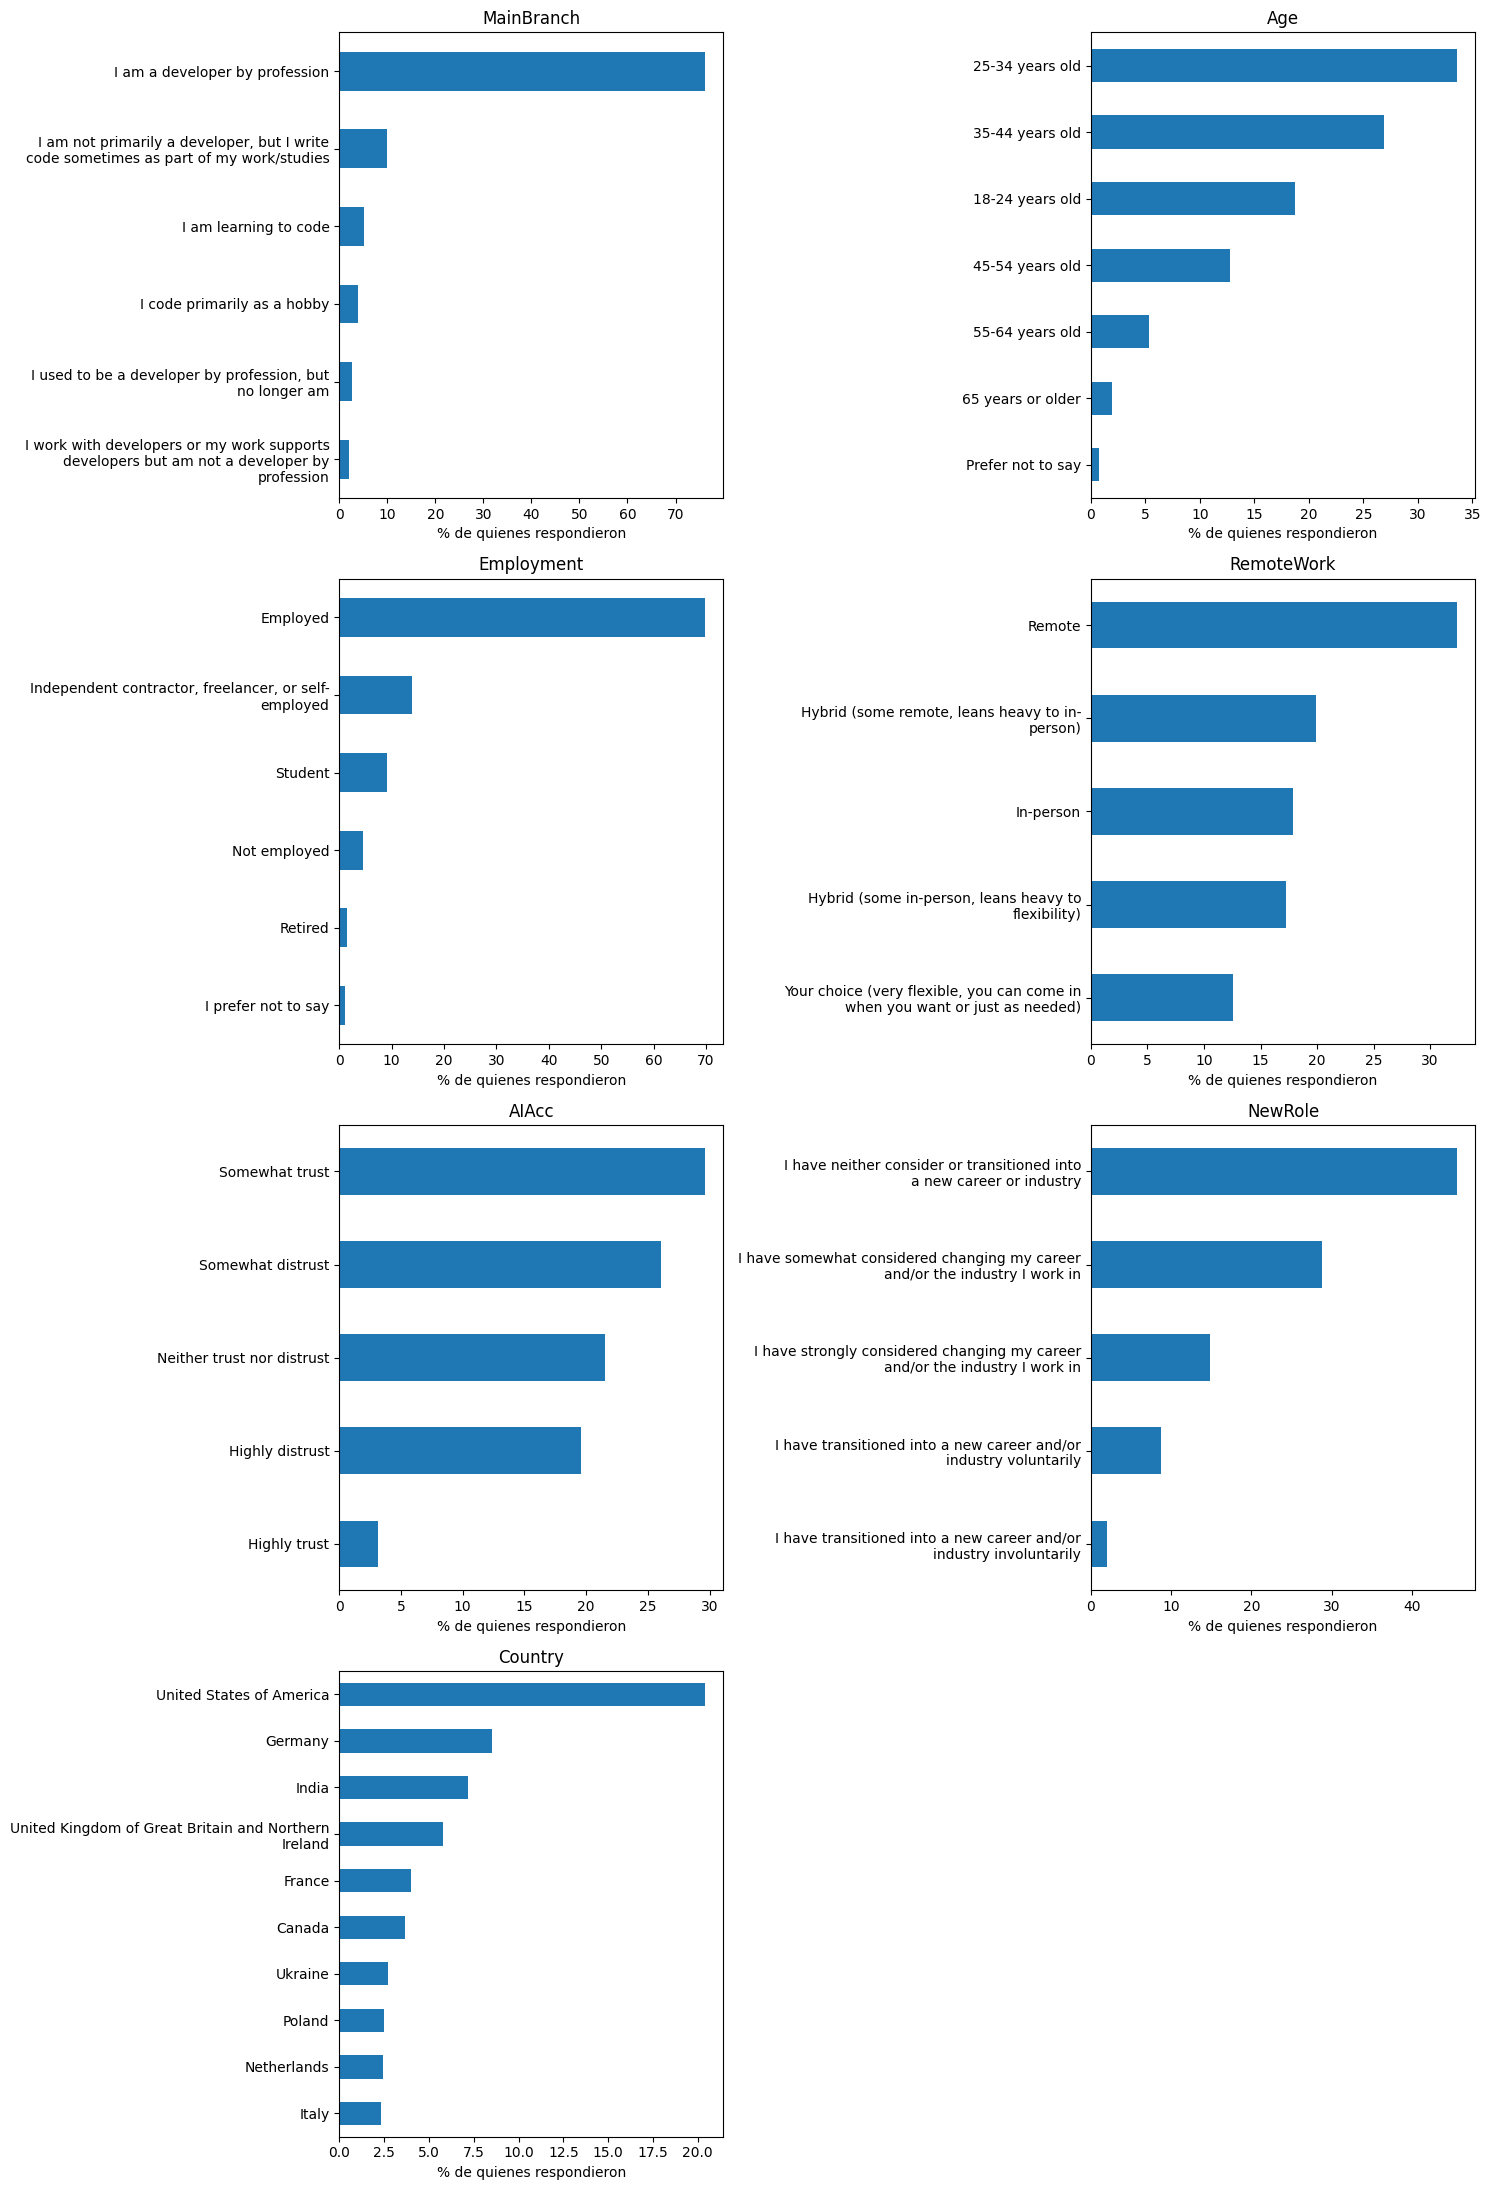

In [4]:
import textwrap

# Distribución de las principales variables categóricas (porcentaje sobre quienes respondieron cada pregunta)
variables_categoricas = ["MainBranch", "Age", "Employment", "RemoteWork", "AIAcc", "NewRole"]

for columna in variables_categoricas:
    print(f"{columna}: respondieron {df[columna].notna().sum()} personas ({df[columna].notna().mean() * 100:.1f} %)")
    display((df[columna].value_counts(normalize=True) * 100).round(1).to_frame("%"))

print(f"Country: {df['Country'].nunique()} países; los 10 con más respuestas:")
display((df["Country"].value_counts(normalize=True).head(10) * 100).round(1).to_frame("%"))
print("Respuestas de Argentina:", (df["Country"] == "Argentina").sum())

fig, ejes = plt.subplots(4, 2, figsize=(15, 22))
for eje, columna in zip(ejes.flat, variables_categoricas + ["Country"]):
    porcentajes = df[columna].value_counts(normalize=True).head(10) * 100
    porcentajes.index = [textwrap.fill(str(etiqueta), 45) for etiqueta in porcentajes.index]
    porcentajes.sort_values().plot(kind="barh", ax=eje)
    eje.set_title(columna)
    eje.set_xlabel("% de quienes respondieron")
    eje.set_ylabel("")
ejes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

La muestra está formada sobre todo por desarrolladores profesionales (76,2 %), jóvenes (el 52,3 % tiene menos de 35 años) y empleados (69,8 %, más un 13,9 % de independientes). Estados Unidos concentra el 20,4 % de las respuestas, seguido por Alemania (8,5 %) e India (7,2 %); Argentina aporta 222. En la modalidad de trabajo predomina el trabajo remoto (32,4 %), y en la confianza en la precisión de la IA hay más desconfianza (45,7 % desconfía algo o mucho) que confianza (32,7 %). Varias preguntas, como `RemoteWork`, `AIAcc` y `NewRole`, solo fueron respondidas por alrededor del 70 % de los participantes, lo que coincide con lo visto en los valores nulos.

Esta composición refuerza el sesgo de selección señalado en la sección 1.1: los resultados describen sobre todo a desarrolladores profesionales, jóvenes y empleados, con mucho peso de Estados Unidos.

**Variables numéricas.** Busquemos ahora las variables cuantitativas, para las cuales vamos a realizar un boxplot en busca de outliers. Luego variable por variable deberemos analizar si estos outliers tienen sentido o son simplemente errores.

In [5]:
# Columnas almacenadas con tipos numéricos
columnas_numericas = df.select_dtypes(
    include="number"
).columns.tolist()

print("Cantidad de columnas numéricas:", len(columnas_numericas))
print(columnas_numericas)

Cantidad de columnas numéricas: 53
['ResponseId', 'WorkExp', 'YearsCode', 'TechEndorse_1', 'TechEndorse_2', 'TechEndorse_3', 'TechEndorse_4', 'TechEndorse_5', 'TechEndorse_6', 'TechEndorse_7', 'TechEndorse_8', 'TechEndorse_9', 'TechEndorse_13', 'TechOppose_1', 'TechOppose_2', 'TechOppose_3', 'TechOppose_5', 'TechOppose_7', 'TechOppose_9', 'TechOppose_11', 'TechOppose_13', 'TechOppose_16', 'TechOppose_15', 'JobSatPoints_1', 'JobSatPoints_2', 'JobSatPoints_3', 'JobSatPoints_4', 'JobSatPoints_5', 'JobSatPoints_6', 'JobSatPoints_7', 'JobSatPoints_8', 'JobSatPoints_9', 'JobSatPoints_10', 'JobSatPoints_11', 'JobSatPoints_13', 'JobSatPoints_14', 'JobSatPoints_15', 'JobSatPoints_16', 'ToolCountWork', 'ToolCountPersonal', 'CompTotal', 'SO_Actions_1', 'SO_Actions_16', 'SO_Actions_3', 'SO_Actions_4', 'SO_Actions_5', 'SO_Actions_6', 'SO_Actions_9', 'SO_Actions_7', 'SO_Actions_10', 'SO_Actions_15', 'ConvertedCompYearly', 'JobSat']


,count,mean,std,min,25%,50%,75%,max
ResponseId,49191.0,2.459600e+04,1.420036e+04,1.0,12298.5,24596.0,36893.5,4.919100e+04
WorkExp,42893.0,1.337000e+01,1.080000e+01,1.0,5.0,10.0,20.0,1.000000e+02
YearsCode,43042.0,1.657000e+01,1.179000e+01,1.0,8.0,14.0,24.0,1.000000e+02
TechEndorse_1,35975.0,7.870000e+00,2.400000e+00,1.0,7.0,9.0,9.0,1.400000e+01
TechEndorse_2,35975.0,4.100000e+00,2.280000e+00,1.0,2.0,4.0,6.0,1.400000e+01
TechEndorse_3,35975.0,4.110000e+00,2.330000e+00,1.0,2.0,4.0,6.0,1.400000e+01
TechEndorse_4,35975.0,5.680000e+00,2.400000e+00,1.0,4.0,6.0,8.0,1.400000e+01
TechEndorse_5,35975.0,4.120000e+00,2.440000e+00,1.0,2.0,4.0,6.0,1.400000e+01
TechEndorse_6,35975.0,5.230000e+00,2.800000e+00,1.0,3.0,5.0,8.0,1.400000e+01
TechEndorse_7,35975.0,6.480000e+00,2.330000e+00,1.0,5.0,7.0,8.0,1.400000e+01


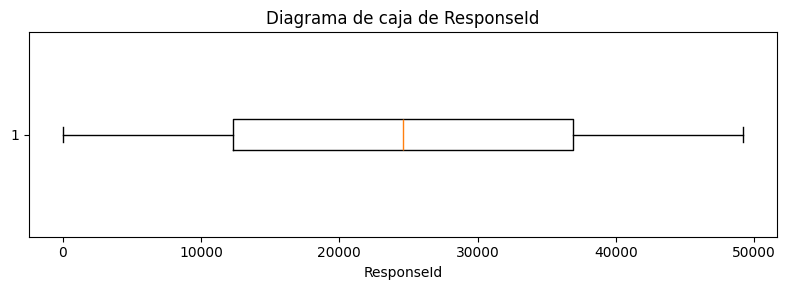

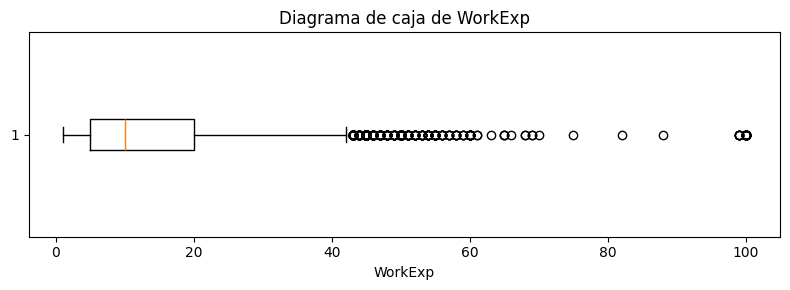

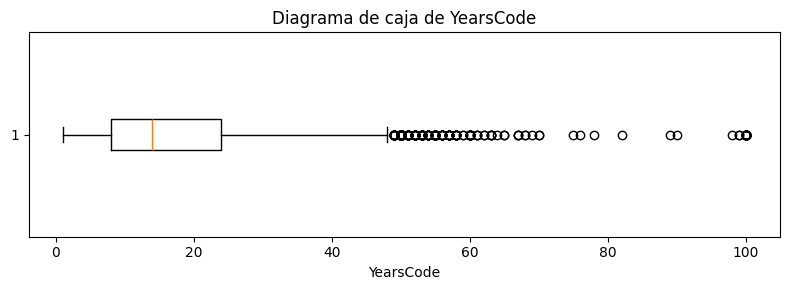

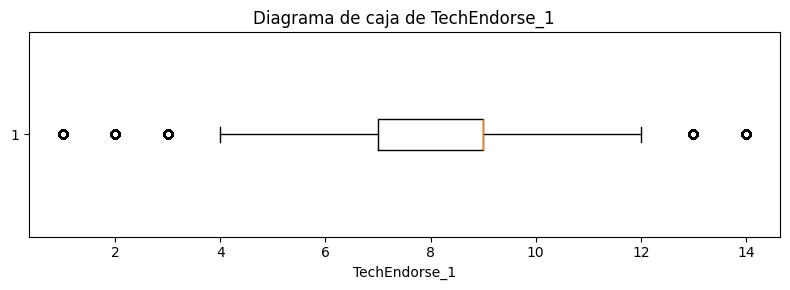

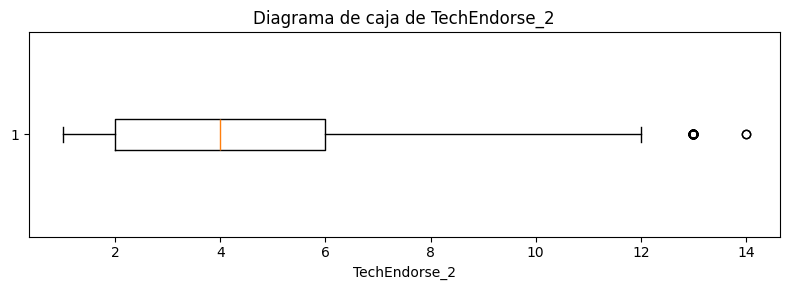

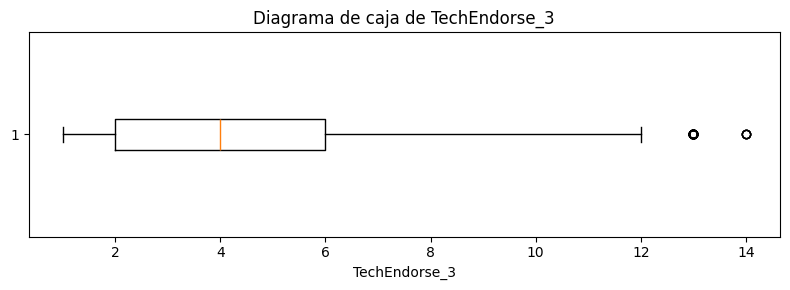

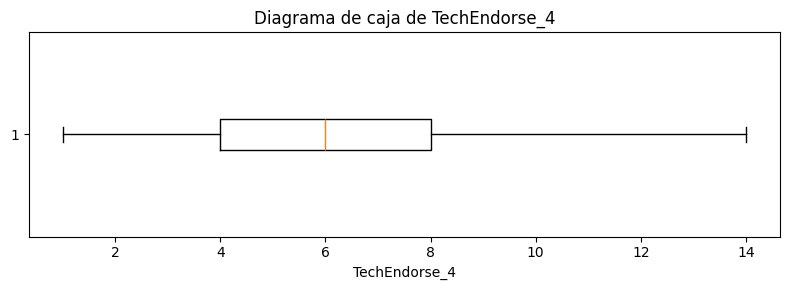

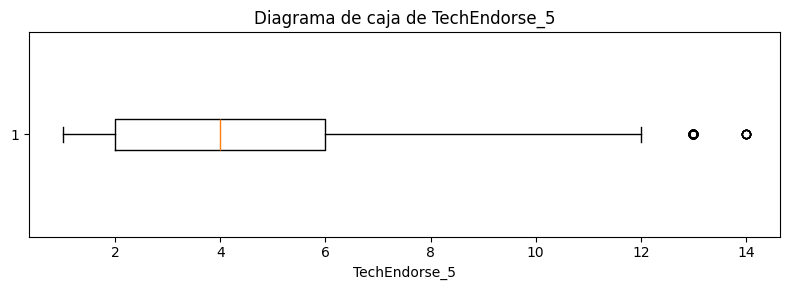

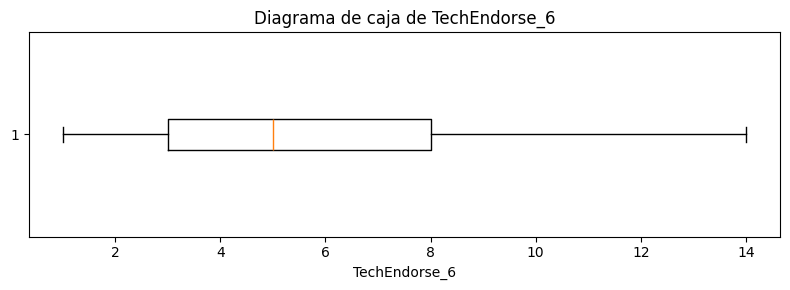

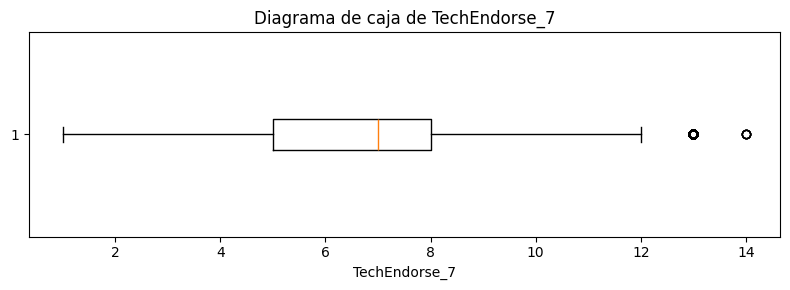

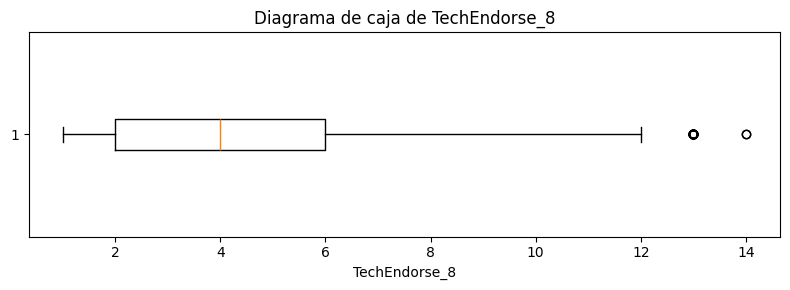

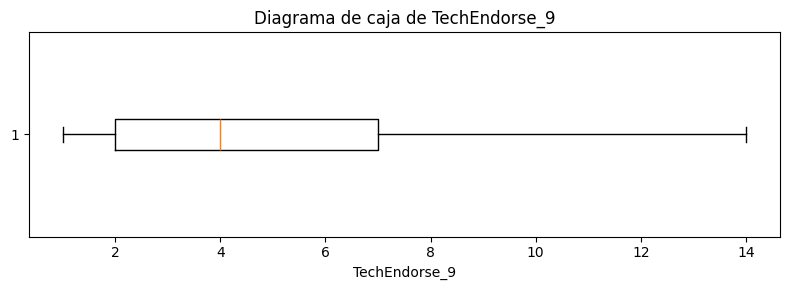

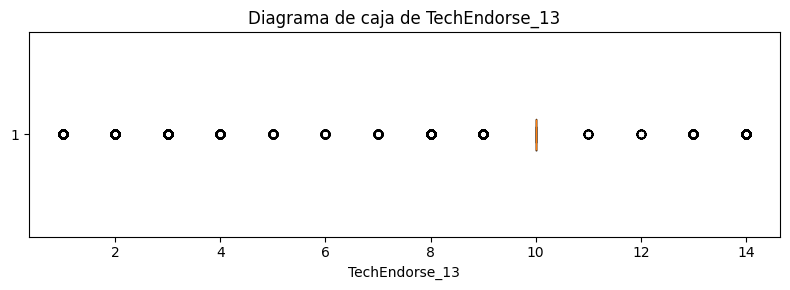

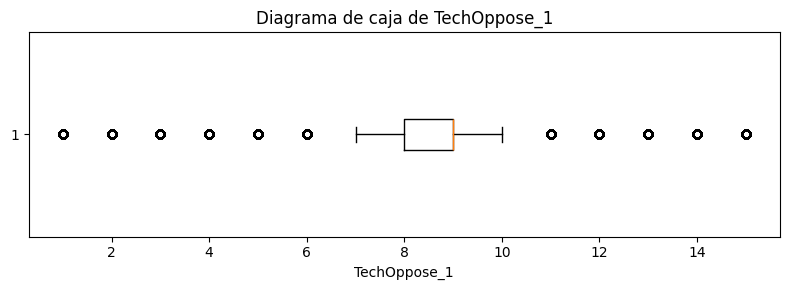

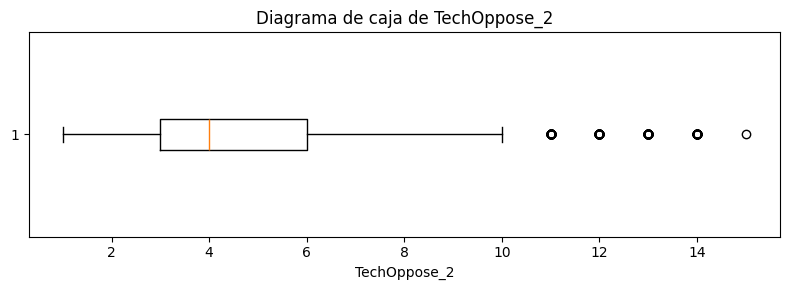

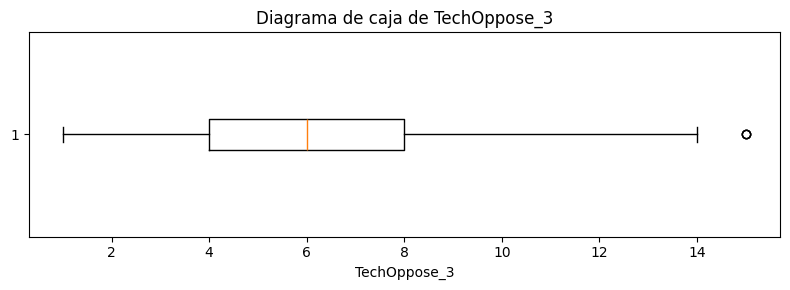

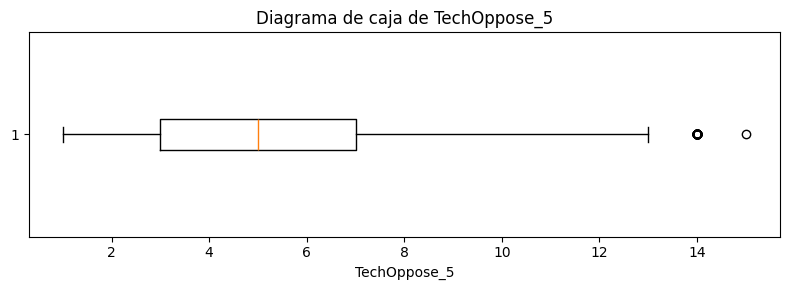

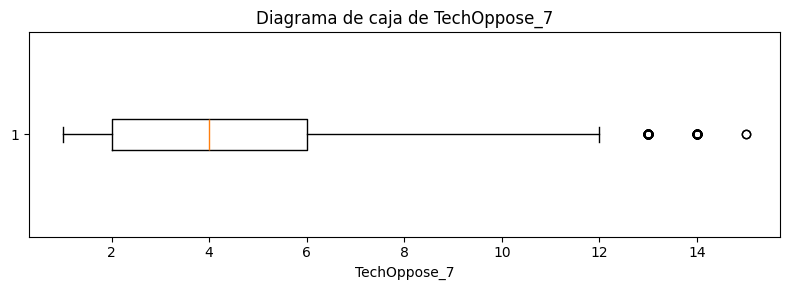

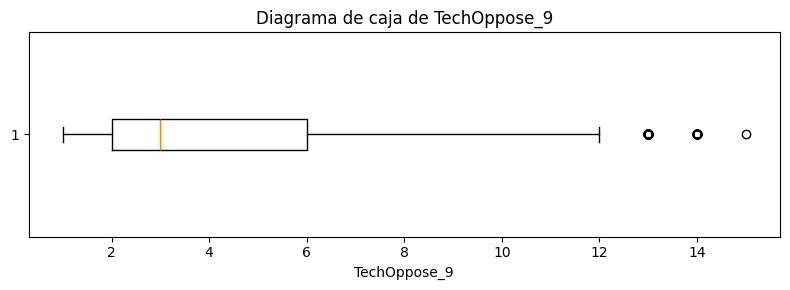

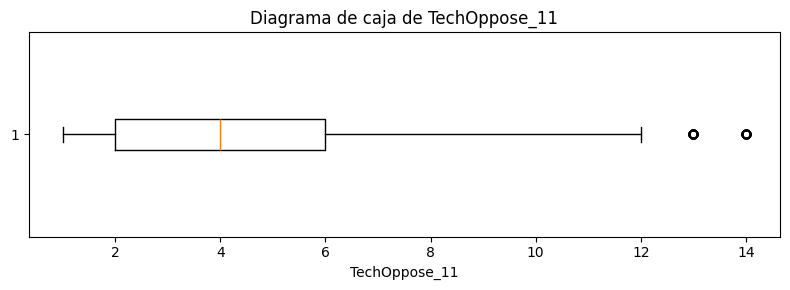

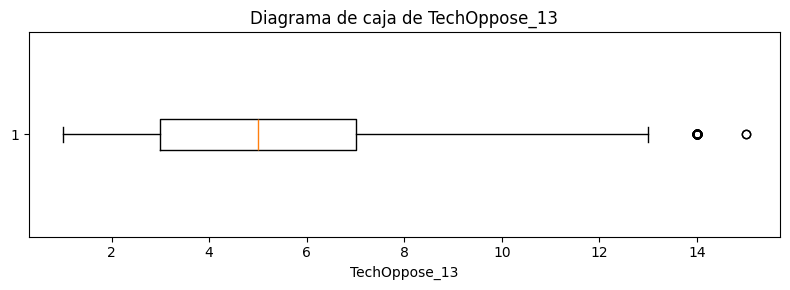

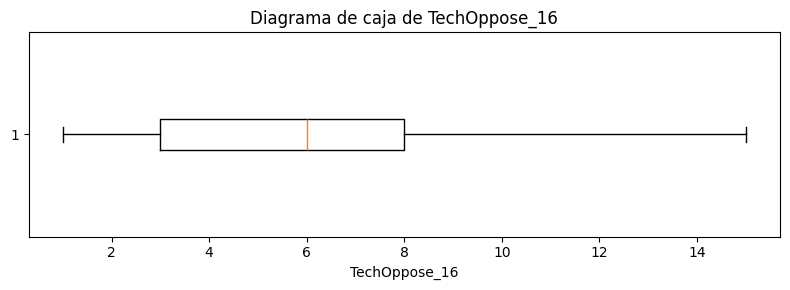

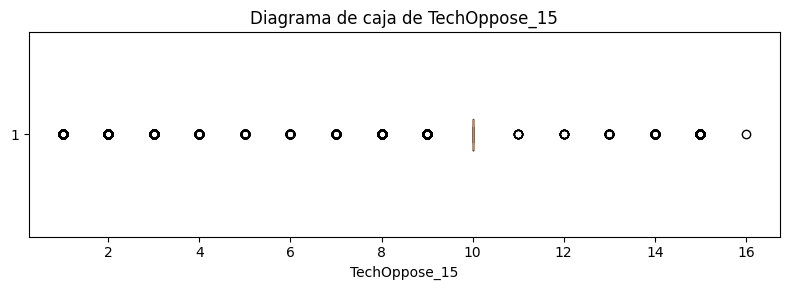

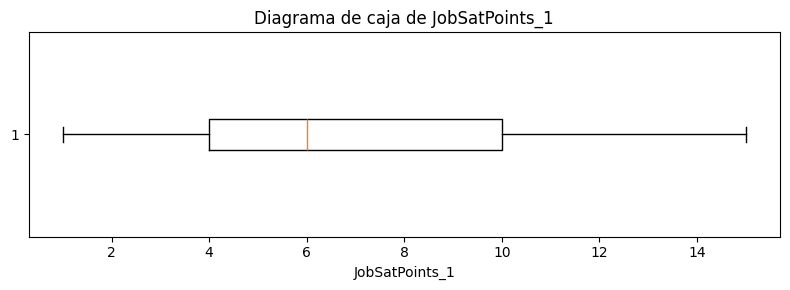

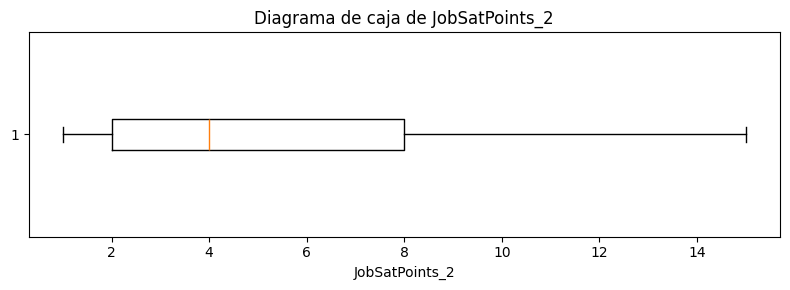

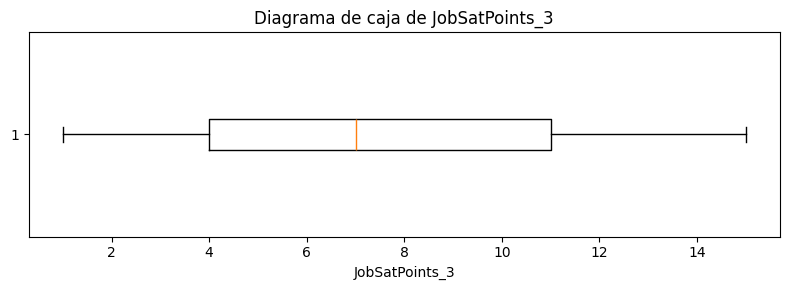

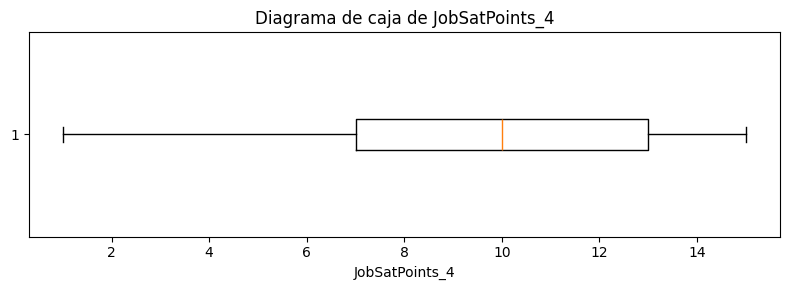

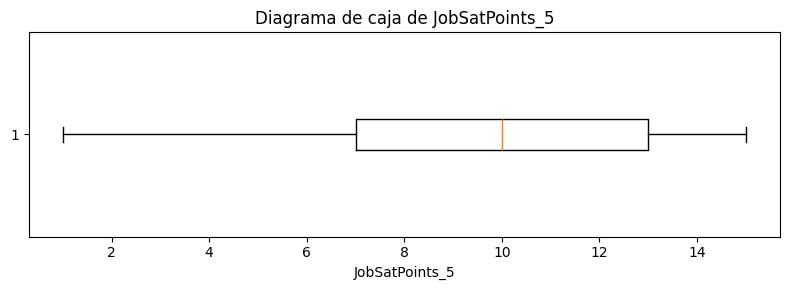

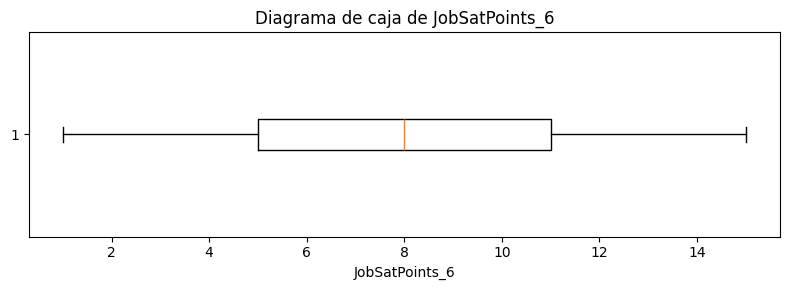

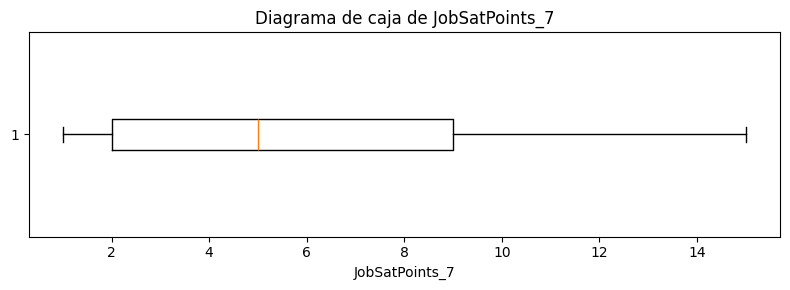

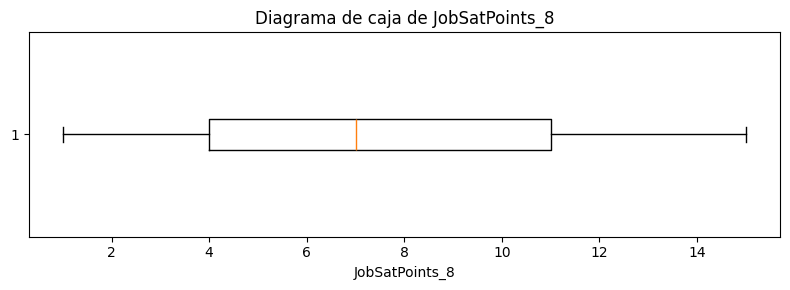

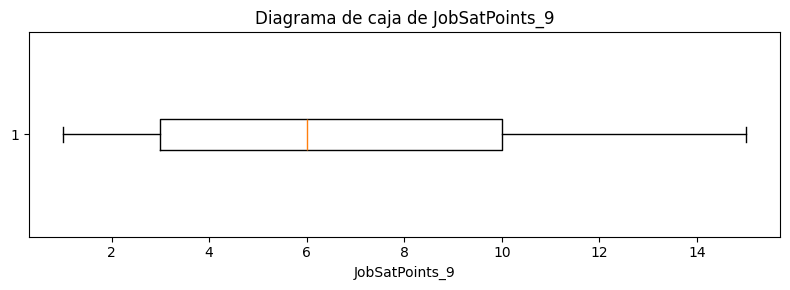

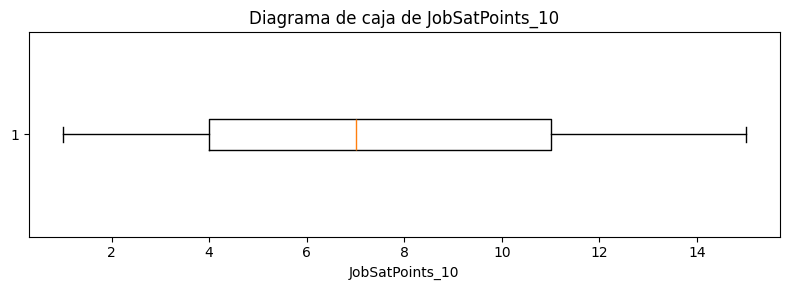

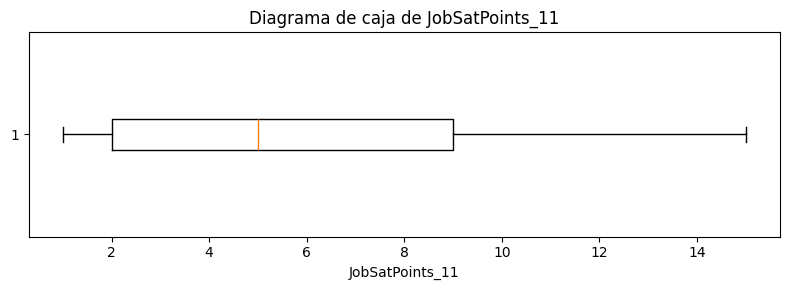

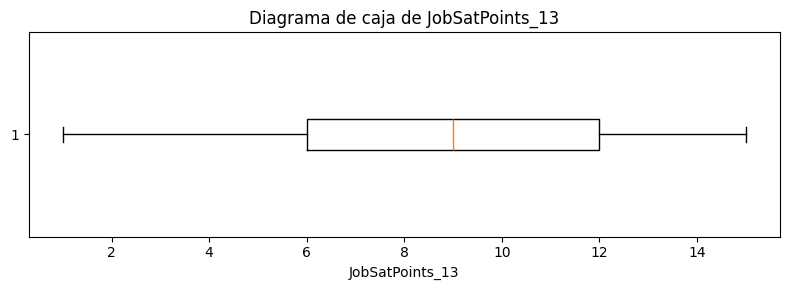

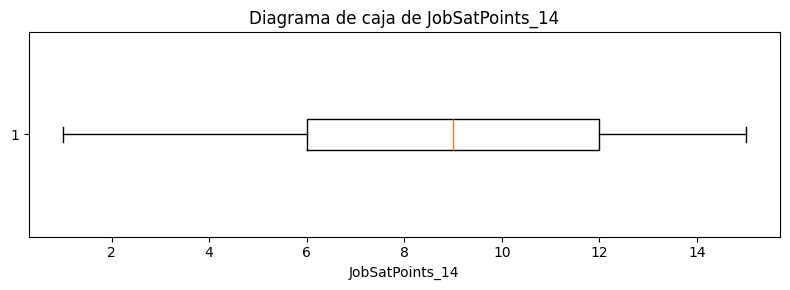

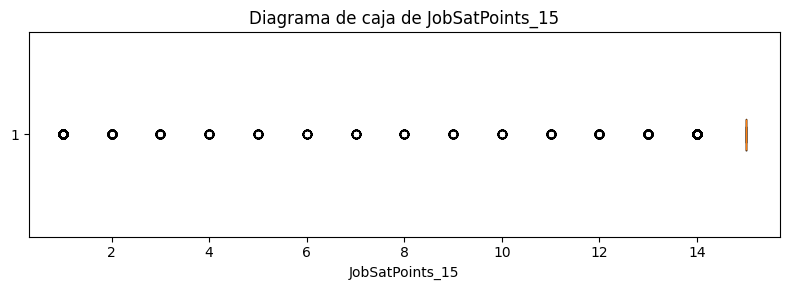

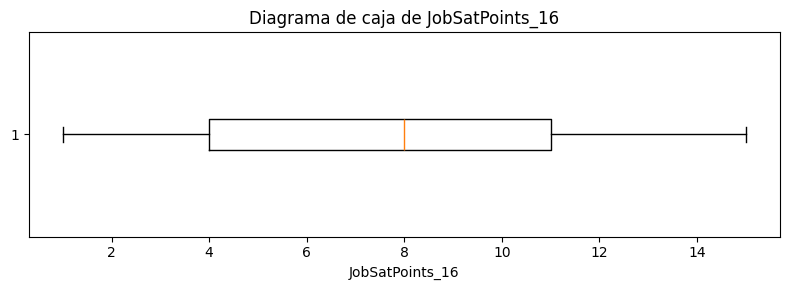

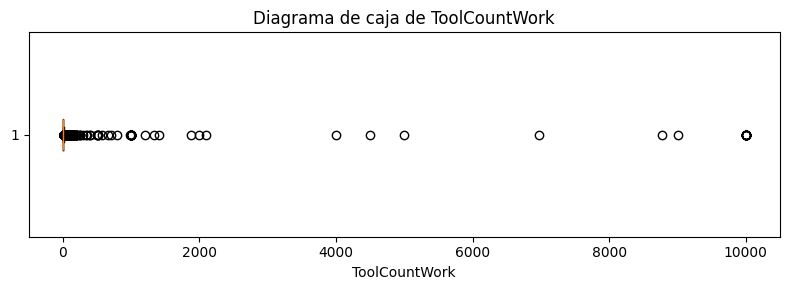

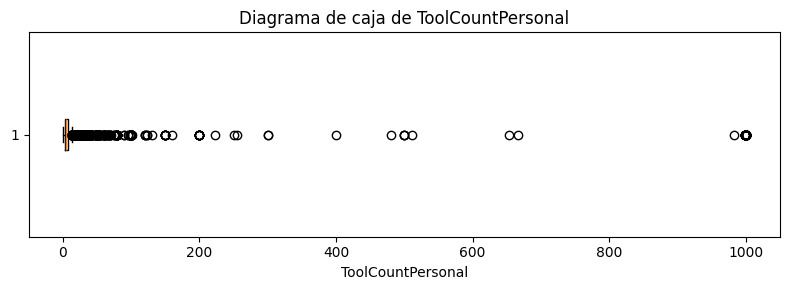

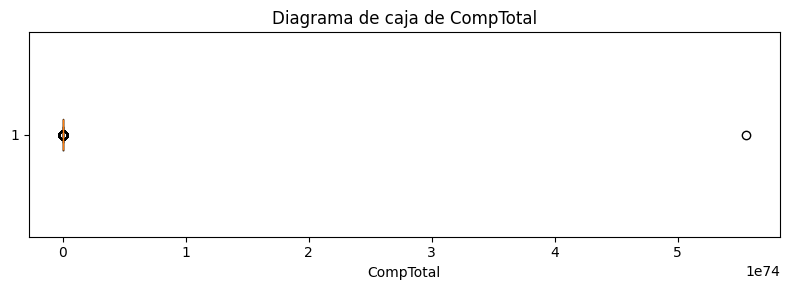

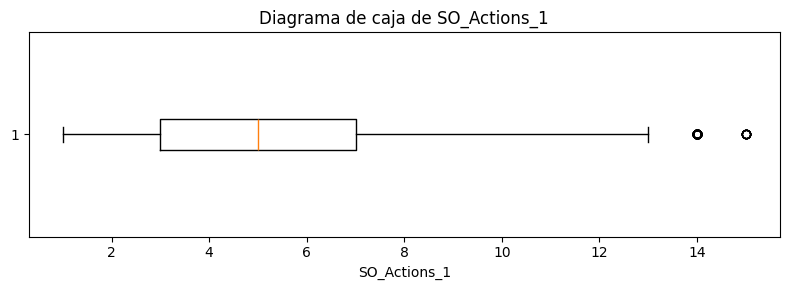

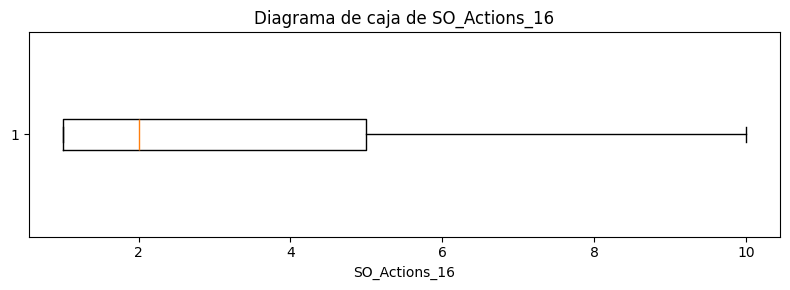

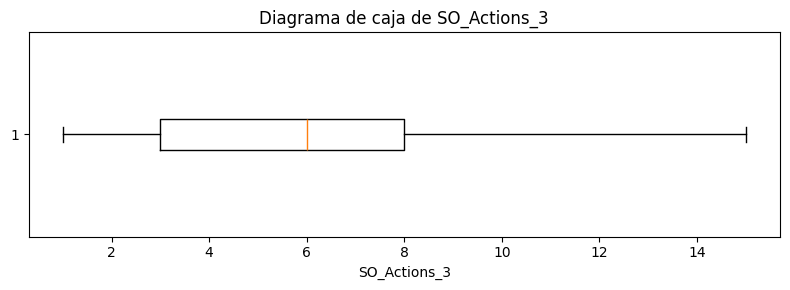

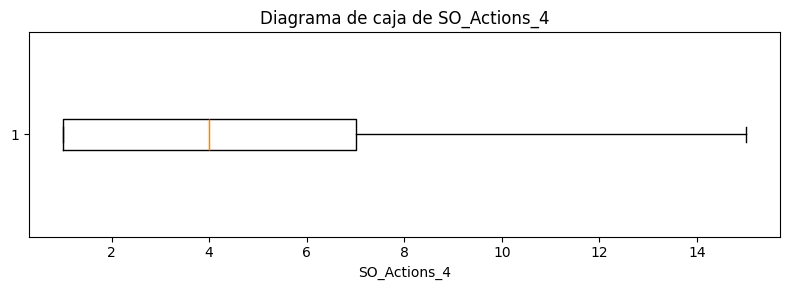

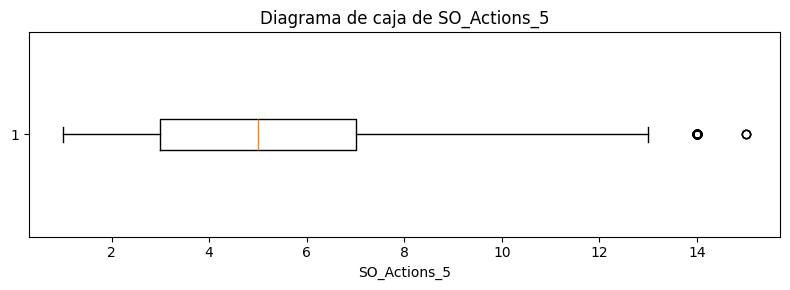

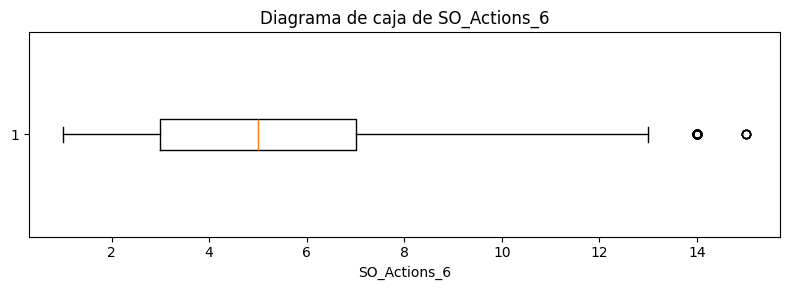

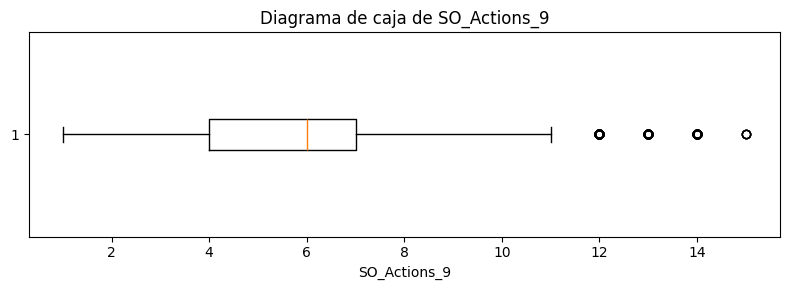

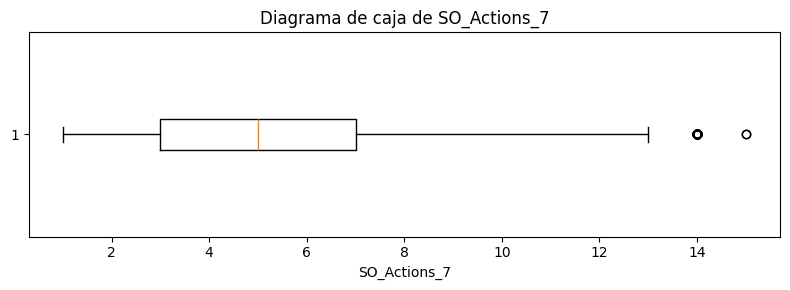

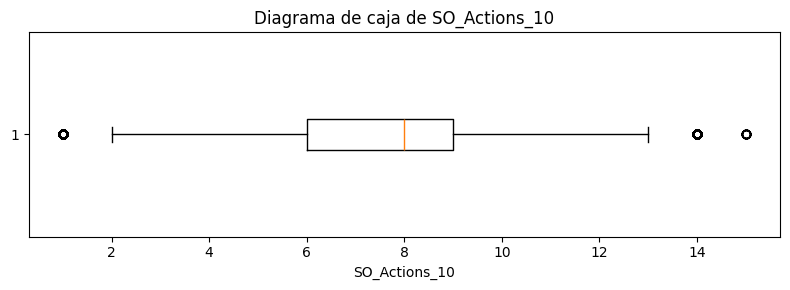

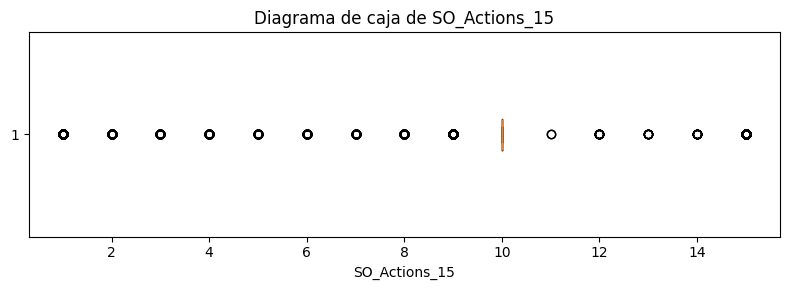

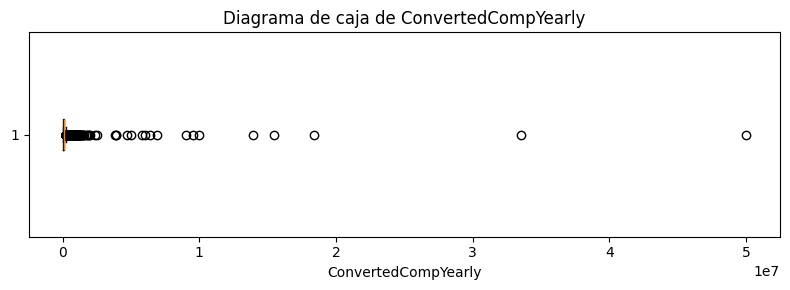

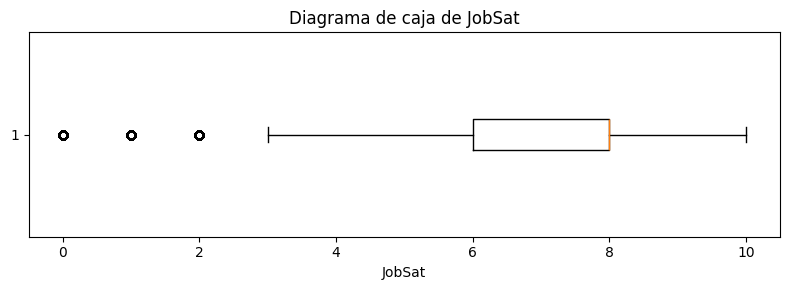

In [6]:
# Calcular estadísticas descriptivas
display(
    df[columnas_numericas]
    .describe()
    .T
    .round(2)
)

for columna in columnas_numericas:
    datos = df[columna].dropna()

    plt.figure(figsize=(8, 3))
    plt.boxplot(datos, vert=False)
    plt.title(f"Diagrama de caja de {columna}")
    plt.xlabel(columna)
    plt.tight_layout()
    plt.show()

Podemos analizar que hay claros outliers en todas estas variables:
* WorkExp
* YearsCode
* TechEndorse_ 1, 2, 3, 5, 7, 8, 13
* TechOppose_ 1, 2, 3, 5, 7, 9, 11, 13, 15
* JobSatPoints_15
* ToolCountWork
* ToolCountPersonal
* CompTotal
* SO_Actions_1, 5, 6, 7, 9, 10, 15
* ConvertedCompYearly
* JobSat

Ahora de a poco iremos analizando su sentido. Primero clasificamos las variables:

In [7]:
# Variables codificadas con un dominio acotado: posiciones de un ranking o una escala de 0 a 10
variables_codificadas = {
    "TechEndorse (ranking)": ["TechEndorse_1", "TechEndorse_2", "TechEndorse_3", "TechEndorse_5",
                              "TechEndorse_7", "TechEndorse_8", "TechEndorse_13"],
    "TechOppose (ranking)": ["TechOppose_1", "TechOppose_2", "TechOppose_3", "TechOppose_5", "TechOppose_7",
                             "TechOppose_9", "TechOppose_11", "TechOppose_13", "TechOppose_15"],
    "JobSatPoints_15 (ranking)": ["JobSatPoints_15"],
    "SO_Actions (ranking)": ["SO_Actions_1", "SO_Actions_5", "SO_Actions_6", "SO_Actions_7",
                             "SO_Actions_9", "SO_Actions_10", "SO_Actions_15"],
    "JobSat (escala de 0 a 10)": ["JobSat"]
}

# Verificamos que todos sus valores estén dentro de un rango acotado
for grupo, columnas in variables_codificadas.items():
    print(f"{grupo}: mínimo = {df[columnas].min().min():.0f}, máximo = {df[columnas].max().max():.0f}")

TechEndorse (ranking): mínimo = 1, máximo = 14
TechOppose (ranking): mínimo = 1, máximo = 16
JobSatPoints_15 (ranking): mínimo = 1, máximo = 15
SO_Actions (ranking): mínimo = 1, máximo = 15
JobSat (escala de 0 a 10): mínimo = 0, máximo = 10


Las variables de TechEndorse, TechOppose, JobSatPoints y SO_Actions son posiciones en un ranking, y JobSat es una escala de 0 a 10: como muestra la celda anterior, todos sus valores están dentro de un rango acotado (entre 0 y 16). Por este motivo, los valores identificados como outliers mediante boxplots no se considerarán automáticamente errores, ya que pueden corresponder a respuestas válidas pero menos frecuentes o alejadas del centro de la distribución. De esta manera se descartarán estas variables como posibles errores, y se continuará con el análisis de las demás.

Entonces seguimos con las variables cuantitativas que hay que revisar una por una:
* CompTotal
* ConvertedCompYearly
* WorkExp
* YearsCode
* ToolCountWork
* ToolCountPersonal

In [8]:
def mostrar_valores_mas_altos(variable, cantidad=10):
    columnas_contexto = {
        "WorkExp": ["ResponseId", "Age", "WorkExp"],
        "YearsCode": ["ResponseId", "Age", "YearsCode"],
        "ToolCountWork": ["ResponseId", "ToolCountWork"],
        "ToolCountPersonal": ["ResponseId", "ToolCountPersonal"],
        "CompTotal": ["ResponseId", "Country", "Currency", "CompTotal"],
        "ConvertedCompYearly": [
            "ResponseId", "Country", "Currency",
            "CompTotal", "ConvertedCompYearly"
        ]
    }

    columnas_revision = [
        col for col in columnas_contexto[variable]
        if col in df.columns
    ]

    print(f"Valores más altos de {variable}:")

    display(
        df.nlargest(cantidad, variable)[columnas_revision]
    )

In [9]:
mostrar_valores_mas_altos("CompTotal")

Valores más altos de CompTotal:


,ResponseId,Country,Currency,CompTotal
4933,4934,United States of America,USD United States dollar,5.555556e+74
44526,44527,Nepal,USD United States dollar,8.000000e+23
35764,35765,India,INR Indian rupee,1.000000e+23
28545,28546,"Micronesia, Federated States of...",USD United States dollar,9.223372e+18
22732,22733,Philippines,USD United States dollar,1.000000e+17
483,484,Zimbabwe,AZN\tAzerbaijan manat,1.000000e+16
18754,18755,United States of America,USD United States dollar,1.000000e+15
39337,39338,Myanmar,MMK\tMyanmar kyat,9.596957e+11
35353,35354,"Iran, Islamic Republic of...",IRR\tIranian rial,6.500000e+11
39349,39350,Viet Nam,VND\tVietnamese dong,1.000000e+11


Podemos analizar que hay cifras notoriamente altas. Habrá que ver la validez según la moneda corriente declarada, pero valores del orden de $10^{74}$ no tienen sentido en ninguna moneda, y mucho menos en USD.

Podríamos usar ConvertedCompYearly, que es básicamente CompTotal pero pasado a una moneda común para facilitar la comparación. Esto nos facilitaría la detección de outliers sin sentido, sin depender de la moneda de cambio. Luego habría que sentar una regla de decisión sobre qué valores se consideran errores y cuáles simplemente sueldos altos.

In [10]:
mostrar_valores_mas_altos("ConvertedCompYearly")

Valores más altos de ConvertedCompYearly:


,ResponseId,Country,Currency,CompTotal,ConvertedCompYearly
34267,34268,United States of America,USD United States dollar,5.000000e+07,50000000.0
28700,28701,Ukraine,UAH Ukrainian hryvnia,1.400000e+09,33552715.0
43143,43144,Poland,BRL Brazilian real,1.010101e+08,18387548.0
35353,35354,"Iran, Islamic Republic of...",IRR\tIranian rial,6.500000e+11,15430267.0
45971,45972,Netherlands,EUR European Euro,1.200000e+07,13921760.0
48428,48429,Ukraine,USD United States dollar,1.000000e+07,10000000.0
24900,24901,India,INR Indian rupee,8.200000e+08,9531653.0
10025,10026,United States of America,USD United States dollar,9.000000e+06,9000000.0
37352,37353,Ukraine,UAH Ukrainian hryvnia,2.875004e+08,6890299.0
30728,30729,Brazil,BRL Brazilian real,3.500000e+07,6371285.0


In [11]:
mostrar_valores_mas_altos("WorkExp")

Valores más altos de WorkExp:


,ResponseId,Age,WorkExp
3285,3286,65 years or older,100.0
4933,4934,45-54 years old,100.0
7881,7882,25-34 years old,100.0
11064,11065,25-34 years old,100.0
12140,12141,35-44 years old,100.0
15655,15656,35-44 years old,100.0
16715,16716,18-24 years old,100.0
18573,18574,25-34 years old,100.0
19680,19681,Prefer not to say,100.0
21455,21456,35-44 years old,100.0


Podemos observar aquí que prácticamente todos los valores son errores de la encuesta. No tiene sentido tener más años de experiencia laboral que de edad, por ende debemos descartar estos valores. Se implementará como regla de dominio que WorkExp no puede superar los años transcurridos desde los 18 años (la edad máxima del rango declarado menos 18), y los registros que no la cumplan se eliminarán en la limpieza (sección 2.2.1).

In [12]:
mostrar_valores_mas_altos("YearsCode")

Valores más altos de YearsCode:


,ResponseId,Age,YearsCode
4933,4934,45-54 years old,100.0
6989,6990,25-34 years old,100.0
7881,7882,25-34 years old,100.0
11064,11065,25-34 years old,100.0
12140,12141,35-44 years old,100.0
15655,15656,35-44 years old,100.0
16695,16696,18-24 years old,100.0
16715,16716,18-24 years old,100.0
19680,19681,Prefer not to say,100.0
20409,20410,18-24 years old,100.0


Podemos deducir acá que pasa exactamente lo mismo que con WorkExp: filas con más años de coding que de edad. No tiene sentido, así que aplicamos una regla análoga, contando desde los 5 años (sección 2.2.1).

In [13]:
mostrar_valores_mas_altos("ToolCountWork")

Valores más altos de ToolCountWork:


,ResponseId,ToolCountWork
5748,5749,10000.0
6785,6786,10000.0
6873,6874,10000.0
6989,6990,10000.0
21455,21456,10000.0
23987,23988,10000.0
26581,26582,10000.0
26587,26588,10000.0
28545,28546,10000.0
28570,28571,10000.0


In [14]:
mostrar_valores_mas_altos("ToolCountPersonal")

Valores más altos de ToolCountPersonal:


,ResponseId,ToolCountPersonal
483,484,1000.0
2942,2943,1000.0
5594,5595,1000.0
6746,6747,1000.0
6785,6786,1000.0
6989,6990,1000.0
8569,8570,1000.0
11064,11065,1000.0
11291,11292,1000.0
11681,11682,1000.0


En estas últimas dos variables claramente tenemos valores outliers, pero no podemos decir todavía que son errores. Los valores parecen irreales (no tiene mucho sentido usar 10.000 herramientas para el trabajo o de manera personal), pero no podemos decidir arbitrariamente qué límite de herramientas utilizadas tiene sentido. Por eso, en la limpieza (sección 2.2.2) definimos el umbral a partir de la distribución de los datos.

# 2. Limpieza de la Base de Datos

In [15]:
df_limpio = df.copy()

## 2.1 Eliminación de columnas redundantes y entradas de texto libre masivo
Eliminamos 39 columnas que no aportan a los análisis estadísticos:

- **Texto libre** (columnas terminadas en `_TEXT` o `Write`, con más del 95 % de valores nulos, y las preguntas abiertas `AIExplain` y `AIOpen`): son respuestas escritas a mano, muy dispersas, que no se pueden analizar con técnicas estadísticas directas.
- **Tecnologías agregadas a mano** (columnas terminadas en `Entry` o `Entr`): tienen entre un 92 % y un 99 % de valores nulos y mucha variabilidad en cómo se escribieron.
- **Preguntas de filtro** (columnas terminadas en `Choice`, `TechEndorseIntro` y `LearnCodeChoose`): solo habilitaban otras secciones de la encuesta; la información útil está en las columnas de tecnologías usadas y deseadas.
- **`CompTotal` y `Currency`**: el salario en moneda local no se puede comparar entre países y tiene valores absurdos; usamos `ConvertedCompYearly`, que está en dólares.
- **`ResponseId`**: es un identificador, no una variable con significado estadístico.

Así reducimos la base de 172 a 133 columnas sin eliminar ninguna respuesta.

In [16]:
# Eliminación de columnas redundantes, administrativas y de texto libre
cols_redundantes = [
    'ResponseId', 'CompTotal', 'Currency',
    'TechEndorseIntro', 'LearnCodeChoose',
    'AIExplain', 'AIOpen'
]

cols_patrones = [
    col for col in df_limpio.columns
    if col.endswith(('_TEXT', 'Write', 'Entry', 'Entr', 'Choice'))
    or col == 'SOTagsWant Entry'
]

cols_a_eliminar = list(set(cols_redundantes + cols_patrones))
df_limpio = df_limpio.drop(columns=cols_a_eliminar, errors='ignore')

print(f"Columnas eliminadas: {len(cols_a_eliminar)}")
print(f"Nuevas dimensiones de la base: {df_limpio.shape}")

Columnas eliminadas: 39
Nuevas dimensiones de la base: (49191, 133)


## 2.2 Tratamiento de inconsistencias y valores atípicos

### 2.2.1 Experiencia frente a la edad (WorkExp y YearsCode)
Se transformó la variable Age, originalmente categórica, en valores numéricos correspondientes al límite superior de cada rango de edad (70 para "65 years or older"). La opción "Prefer not to say" quedó como valor faltante, porque no corresponde a ninguna edad.

Además, se establecieron límites máximos de años de experiencia (WorkExp y YearsCode) según la categoría de edad. Se identificaron y eliminaron los registros que superaban dichos límites, considerando que presentaban inconsistencias lógicas entre la edad declarada y la experiencia acumulada.

Para WorkExp tomamos el límite superior del rango de edad, y concluimos que como máximo la persona puede haber trabajado desde los 18 años (legalmente). Para YearsCode hicimos lo mismo, pero considerando que la persona puede haber aprendido a partir de los 5 años. Este valor es arbitrario, pero tratamos de ser permisivos considerando que hoy en día se enseña programación desde el nivel primario o incluso antes. Para "65 years or older" y "Prefer not to say", que no tienen un límite superior, usamos límites fijos de 60 años de experiencia laboral y 65 años programando.

Los valores faltantes de WorkExp se completaron con 0, porque la encuesta pedía dejar el campo vacío cuando la experiencia laboral era 0. YearsCode no tiene esa indicación; sus faltantes también se completaron con 0, pero esta variable solo se usa en este control y no en ninguna hipótesis, por lo que no afecta los resultados.

In [17]:
# Guardar las categorías originales
age_original = df_limpio["Age"].copy()

# Transformar Age a valores numéricos
age_encoding = {
    "18-24 years old": 24,
    "25-34 years old": 34,
    "35-44 years old": 44,
    "45-54 years old": 54,
    "55-64 years old": 64,
    "65 years or older": 70,
    "Prefer not to say": np.nan
}

df_limpio["Age"] = age_original.map(age_encoding)

# Definir límites máximos de experiencia
limites_workexp = {
    "18-24 years old": 6,
    "25-34 years old": 16,
    "35-44 years old": 26,
    "45-54 years old": 36,
    "55-64 years old": 46,
    "65 years or older": 60,
    "Prefer not to say": 60
}

limites_yearscode = {
    "18-24 years old": 19,
    "25-34 years old": 29,
    "35-44 years old": 39,
    "45-54 years old": 49,
    "55-64 years old": 59,
    "65 years or older": 65,
    "Prefer not to say": 65
}

max_workexp = age_original.map(limites_workexp)
max_yearscode = age_original.map(limites_yearscode)

# Completamos con 0 los nulos de WorkExp (la encuesta pedía dejarlo vacío si era 0) y de YearsCode
df_limpio["WorkExp"] = df_limpio["WorkExp"].fillna(0)
df_limpio["YearsCode"] = df_limpio["YearsCode"].fillna(0)

# Identificar experiencias que superan el límite
mascara_experiencia = (
    (df_limpio["WorkExp"] > max_workexp)
)

mascara_yearscode = (
    (df_limpio["YearsCode"] > max_yearscode)
)

# Unificar ambas condiciones
mascara = mascara_experiencia | mascara_yearscode

print("Registros que superan el límite de WorkExp:", mascara_experiencia.sum())
print("Registros que superan el límite de YearsCode:", mascara_yearscode.sum())
print("Registros inconsistentes en total:", mascara.sum())

# Eliminar registros inconsistentes
df_limpio = df_limpio.loc[~mascara].copy()

# Verificar resultados
display(df_limpio[["Age", "WorkExp", "YearsCode"]].describe())

print(f"Dimensiones después de la limpieza de experiencia y edad: {df_limpio.shape}")

Registros que superan el límite de WorkExp: 538
Registros que superan el límite de YearsCode: 90
Registros inconsistentes en total: 579


,Age,WorkExp,YearsCode
count,48243.000000,48612.000000,48612.000000
mean,39.754576,11.480560,14.360816
std,11.737400,10.640666,11.968241
min,24.000000,0.000000,0.000000
25%,34.000000,3.000000,5.000000
50%,34.000000,9.000000,12.000000
75%,44.000000,18.000000,20.000000
max,70.000000,60.000000,65.000000


Dimensiones después de la limpieza de experiencia y edad: (48612, 133)


### 2.2.2 Valores extremos en el salario y en la cantidad de herramientas
**Salario.** El análisis exploratorio mostró salarios del orden de $10^{74}$ y salarios anuales de apenas 1 dólar, que corresponden a errores de tipeo o a confusiones con la unidad de tiempo. Para que no distorsionen las estadísticas, trabajamos solo con `ConvertedCompYearly` (en dólares) y conservamos los salarios entre 1.000 dólares anuales y el percentil 99. En la celda siguiente se ve por qué elegimos ese mínimo: el 3,0 % de los salarios es menor a 1.000 USD anuales (menos de 85 USD por mes), con valores como 1, 2, 6 o 10 dólares, y el percentil 1 es de apenas 67 USD al año. No son salarios anuales creíbles, sino errores de carga o montos expresados en otra unidad de tiempo. Los registros sin salario se conservan, porque el resto de sus respuestas sigue siendo útil para las demás hipótesis.

**Herramientas.** `ToolCountWork` y `ToolCountPersonal` llegan a valores de 10.000 y 1.000, respectivamente. Para no elegir un límite arbitrario, miramos su distribución en la celda siguiente: el 99 % de las respuestas es de 50 herramientas o menos, y por encima de 100 quedan muy pocos casos (alrededor del 0,3 %), entre ellos valores como 999, 1.000 o 10.000, típicos de errores de carga. Por eso fijamos un máximo de 100 herramientas, el doble del percentil 99. Los valores faltantes se completaron con 0, suponiendo que quien no respondió no usa herramientas en ese ámbito; como estas variables no se usan en ninguna hipótesis, esta decisión no afecta los resultados.

In [18]:
# Distribución de la cantidad de herramientas, para justificar el umbral de 100
for columna in ["ToolCountWork", "ToolCountPersonal"]:
    datos = df_limpio[columna].dropna()
    mayores_100 = datos[datos > 100]
    print(f"{columna}: percentil 99 = {datos.quantile(0.99):.0f}; "
          f"valores mayores a 100 = {len(mayores_100)} ({len(mayores_100) / len(datos) * 100:.2f} %)")
    print("   Valores más frecuentes por encima de 100:", mayores_100.value_counts().head(5).to_dict())

# Salarios anuales muy bajos, para justificar el mínimo de 1.000 USD
salarios = df_limpio["ConvertedCompYearly"].dropna()
menores_1000 = salarios[salarios < 1000]
print(f"\nSalarios menores a 1.000 USD anuales: {len(menores_1000)} ({len(menores_1000) / len(salarios) * 100:.1f} %)")
print("   Valores más frecuentes:", menores_1000.value_counts().head(6).to_dict())
print(f"   Percentil 1 del salario: {salarios.quantile(0.01):.0f} USD anuales")

ToolCountWork: percentil 99 = 50; valores mayores a 100 = 84 (0.31 %)
   Valores más frecuentes por encima de 100: {1000.0: 12, 10000.0: 10, 150.0: 8, 999.0: 8, 200.0: 7}
ToolCountPersonal: percentil 99 = 50; valores mayores a 100 = 71 (0.28 %)
   Valores más frecuentes por encima de 100: {1000.0: 25, 200.0: 9, 999.0: 9, 150.0: 7, 120.0: 3}

Salarios menores a 1.000 USD anuales: 707 (3.0 %)
   Valores más frecuentes: {1.0: 27, 2.0: 17, 6.0: 13, 10.0: 11, 500.0: 11, 3.0: 7}
   Percentil 1 del salario: 67 USD anuales


In [19]:
# Filtramos valores extremos en la remuneración anual convertida (Percentil 99 y límite inferior)
limite_superior_salarial = df_limpio['ConvertedCompYearly'].quantile(0.99)
limite_inferior_salarial = 1000

df_limpio = df_limpio[
    (
        (df_limpio['ConvertedCompYearly'] >= limite_inferior_salarial) &
        (df_limpio['ConvertedCompYearly'] <= limite_superior_salarial)
    ) |
    (df_limpio['ConvertedCompYearly'].isna())
]

# Rellenamos con 0 los valores nulos en los contadores de herramientas (nulo = no utiliza herramientas)
df_limpio['ToolCountWork'] = df_limpio['ToolCountWork'].fillna(0)
df_limpio['ToolCountPersonal'] = df_limpio['ToolCountPersonal'].fillna(0)

# Filtramos anomalías superiores al límite lógico de 100 herramientas
df_limpio = df_limpio[df_limpio['ToolCountWork'] <= 100]
df_limpio = df_limpio[df_limpio['ToolCountPersonal'] <= 100]

print(f"Dimensiones tras limpiar valores extremos: {df_limpio.shape}")

Dimensiones tras limpiar valores extremos: (47567, 133)


## 2.3 Codificación de variables

Para usar algunas variables cualitativas en los modelos, las codificamos numéricamente. `Age` ya se codificó en la sección 2.2.1, porque se necesitaba para calcular los límites de experiencia.

### 2.3.1 EdLevel
Se aplicó una codificación ordinal, asignando valores enteros del 1 al 7 según el nivel educativo alcanzado. La categoría Other, al no tener una posición ordinal definida, y los valores faltantes se conservaron como NaN.

In [20]:
# Codificar EdLevel
def codificar_edlevel(x):
    if pd.isna(x):
        return np.nan
    elif x.startswith("Primary/elementary"):
        return 1
    elif x.startswith("Secondary"):
        return 2
    elif x.startswith("Some college/university"):
        return 3
    elif x.startswith("Associate degree"):
        return 4
    elif x.startswith("Bachelor"):
        return 5
    elif x.startswith("Master"):
        return 6
    elif x.startswith("Professional degree"):
        return 7
    else:
        return np.nan

df_limpio["EdLevel"] = df_limpio["EdLevel"].map(codificar_edlevel)

# Verificar resultados
print(df_limpio["EdLevel"].value_counts(dropna=False).sort_index())

EdLevel
1.0      536
2.0     3451
3.0     5937
4.0     1502
5.0    19679
6.0    12272
7.0     2521
NaN     1669
Name: count, dtype: int64


### 2.3.2 LearnCodeAI
Se creó una nueva variable binaria (LearnCodeAI_Bin) para agrupar las respuestas en dos categorías: aprendió herramientas de IA (1) y no aprendió (0). Se conservó la variable original y los valores faltantes se mantuvieron como NaN.

In [21]:
# Crear una nueva variable binaria sin modificar LearnCodeAI
df_limpio["LearnCodeAI_Bin"] = df_limpio["LearnCodeAI"].map(
    lambda x: 1 if isinstance(x, str) and x.startswith("Yes")
    else 0 if isinstance(x, str) and x.startswith("No")
    else np.nan
)

# Verificar resultados
print(df_limpio["LearnCodeAI_Bin"].value_counts(dropna=False))

LearnCodeAI_Bin
1.0    29331
0.0    14275
NaN     3961
Name: count, dtype: int64


# 3. Planteo y validación de las hipótesis propias


## A. Hipótesis univariada

**Propuesta:** la mayoría de los desarrolladores (más de la mitad) **no consideró** cambiar de carrera o de industria ni cambió de rol durante el último año.

**Justificación:** el desarrollo de software se percibe tradicionalmente como una profesión estable, con alta demanda laboral y buenas remuneraciones. Por eso esperamos que la mayor parte de las personas encuestadas no esté pensando en abandonar su carrera. Al mismo tiempo, los últimos años estuvieron marcados por despidos en empresas tecnológicas y por la incertidumbre que genera la inteligencia artificial, lo que hace interesante verificar si esa estabilidad se sigue observando.

**Variable utilizada:** `NewRole` (cualitativa nominal), que responde a la pregunta de si la persona consideró un cambio de carrera o pasó a un nuevo rol en el último año. Tiene cinco respuestas posibles: no lo consideró, lo consideró algo, lo consideró mucho, cambió voluntariamente o cambió involuntariamente.

Definimos como **"éxito"** a la respuesta *"I have neither consider or transitioned into a new career or industry"* (no consideró ni realizó un cambio) y llamamos $p$ a la proporción poblacional de esa respuesta.

- $H_0$: $p \leq 0{,}5$ (la mitad o menos no consideró un cambio)
- $H_1$: $p > 0{,}5$ (más de la mitad no consideró un cambio)

**Técnica:** test de hipótesis para una proporción (test Z), con nivel de significancia $\alpha = 0{,}05$. Es la técnica adecuada porque la variable se reduce a dos categorías (éxito / no éxito) y queremos comparar la proporción observada con un valor fijo (0,5). El test es unilateral a derecha porque la hipótesis afirma "más de la mitad".

Primero observamos la distribución de la variable. Trabajamos solo con quienes respondieron la pregunta. Casi todos los valores nulos (el 91,6 %, ver la celda siguiente) corresponden a personas que abandonaron la encuesta antes de esa pregunta, porque tampoco respondieron ninguna de las siguientes, así que no podemos asignarles ninguna respuesta.

Respuestas válidas: 34091
Valores nulos descartados: 13476
Nulos que no respondieron ninguna pregunta posterior: 91.6 %


,Cantidad,Porcentaje
NewRole,,
No consideró ni cambió,15591,45.73
Consideró algo,9892,29.02
Consideró mucho,4956,14.54
Cambió voluntariamente,2978,8.74
Cambió involuntariamente,674,1.98


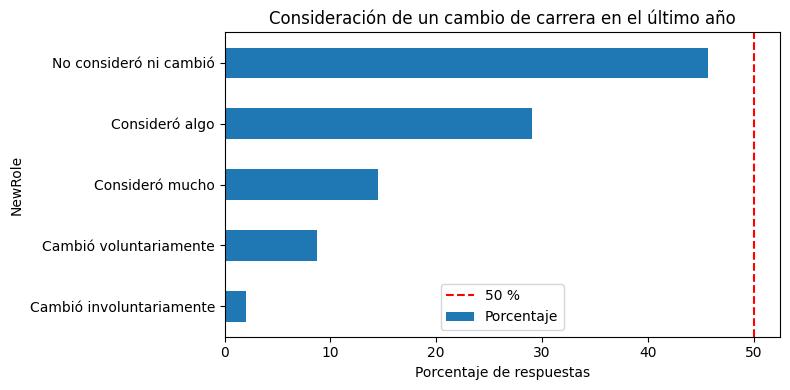

In [22]:
nombres_newrole = {
    "I have neither consider or transitioned into a new career or industry": "No consideró ni cambió",
    "I have somewhat considered changing my career and/or the industry I work in": "Consideró algo",
    "I have strongly considered changing my career and/or the industry I work in": "Consideró mucho",
    "I have transitioned into a new career and/or industry voluntarily": "Cambió voluntariamente",
    "I have transitioned into a new career and/or industry involuntarily": "Cambió involuntariamente"
}

newrole_huni = df_limpio["NewRole"].dropna().map(nombres_newrole)

print("Respuestas válidas:", len(newrole_huni))
print("Valores nulos descartados:", df_limpio["NewRole"].isna().sum())

# ¿Los nulos son personas que abandonaron la encuesta? Revisamos si respondieron alguna pregunta posterior
# (usamos df porque en df_limpio los nulos de ToolCount se completaron con 0)
preguntas_posteriores = df.columns[df.columns.get_loc("NewRole") + 1:]
nulos_newrole = df_limpio.index[df_limpio["NewRole"].isna()]
abandonaron = df.loc[nulos_newrole, preguntas_posteriores].isna().all(axis=1)
print(f"Nulos que no respondieron ninguna pregunta posterior: {abandonaron.mean() * 100:.1f} %")

tabla_huni = pd.DataFrame({
    "Cantidad": newrole_huni.value_counts(),
    "Porcentaje": (newrole_huni.value_counts(normalize=True) * 100).round(2)
})
display(tabla_huni)

plt.figure(figsize=(8, 4))
tabla_huni["Porcentaje"].sort_values().plot(kind="barh")
plt.axvline(50, color="red", linestyle="--", label="50 %")
plt.title("Consideración de un cambio de carrera en el último año")
plt.xlabel("Porcentaje de respuestas")
plt.legend()
plt.tight_layout()
plt.show()

Ahora aplicamos el test Z para una proporción. El estadístico es:

$$Z = \frac{\hat{p} - p_0}{\sqrt{\frac{p_0 (1 - p_0)}{n}}}$$

donde $\hat{p}$ es la proporción observada, $p_0 = 0{,}5$ y $n$ la cantidad de respuestas. El test requiere que $n \cdot p_0 \geq 5$ y $n \cdot (1 - p_0) \geq 5$, lo que se cumple ampliamente.

In [23]:
n_huni = len(newrole_huni)
exitos_huni = (newrole_huni == "No consideró ni cambió").sum()
p_hat = exitos_huni / n_huni
p0 = 0.5
alfa = 0.05

# Estadístico Z y p-valor unilateral a derecha (H1: p > 0,5)
z_huni = (p_hat - p0) / np.sqrt(p0 * (1 - p0) / n_huni)
p_valor_huni = 1 - stats.norm.cdf(z_huni)

# Intervalo de confianza del 95 % para la proporción
error_estandar = np.sqrt(p_hat * (1 - p_hat) / n_huni)
ic_inferior = p_hat - 1.96 * error_estandar
ic_superior = p_hat + 1.96 * error_estandar

print(f"Condición n*p0 = {n_huni * p0:.0f} >= 5")
print(f"n = {n_huni}")
print(f"Proporción observada = {p_hat:.4f} ({p_hat * 100:.2f} %)")
print(f"Z = {z_huni:.2f}")
print(f"p-valor (unilateral a derecha) = {p_valor_huni:.4f}")
print(f"IC 95 % para p: [{ic_inferior:.4f} ; {ic_superior:.4f}]")

if p_valor_huni < alfa:
    print("Se rechaza H0: más de la mitad no consideró un cambio.")
else:
    print("No se rechaza H0: no hay evidencia de que más de la mitad no haya considerado un cambio.")

Condición n*p0 = 17046 >= 5
n = 34091
Proporción observada = 0.4573 (45.73 %)
Z = -15.76
p-valor (unilateral a derecha) = 1.0000
IC 95 % para p: [0.4520 ; 0.4626]
No se rechaza H0: no hay evidencia de que más de la mitad no haya considerado un cambio.


**Resultado:** solo el **45,73 %** de las 34.091 personas que respondieron no consideró ni realizó un cambio de carrera. El estadístico es $Z = -15{,}76$ y el p-valor unilateral es prácticamente 1, por lo que **no se rechaza $H_0$**: los datos no respaldan que más de la mitad de los desarrolladores no haya pensado en cambiar.

Además, el intervalo de confianza del 95 % para la proporción, **[45,20 % ; 46,26 %]**, queda completamente por debajo del 50 %. Es decir, ocurre lo contrario de lo que planteamos: **la mayoría (54,3 %) consideró un cambio o ya lo realizó**. Un 29 % lo consideró algo, un 14,5 % lo consideró mucho y un 10,7 % ya cambió.

**Conclusión:** la hipótesis **no se confirma**. A pesar de la imagen de estabilidad de la profesión, más de la mitad de los encuestados pensó en cambiar de carrera o ya lo hizo durante el último año. Hay que tener en cuenta que la encuesta es voluntaria y no aleatoria, por lo que el resultado describe a quienes participaron y no necesariamente a todos los desarrolladores.

## B. Hipótesis bivariada

**Propuesta**: Los desarrolladores que trabajan bajo modalidad remota perciben una compensación anual en dólares (ConvertedCompYearly) significativamente mayor que aquellos que trabajan de forma presencial.

**Justificación**: El trabajo remoto elimina las barreras geográficas, permitiendo a los profesionales de sistemas acceder a mercados internacionales y empresas con escalas salariales mucho más altas que las dictadas por su mercado local. Por lo tanto, esperamos que la mediana salarial de quienes trabajan a distancia supere a los esquemas tradicionales de oficina.

**Variables utilizadas:** RemoteWork (cualitativa nominal, que indica el esquema presencial, híbrido o remoto) y ConvertedCompYearly (cuantitativa continua, que refleja el salario anual estandarizado en USD).

Definimos como $Me_R$ a la mediana poblacional de la compensación anual de los desarrolladores con modalidad remota, y como $Me_P$ a la mediana poblacional de quienes trabajan de forma presencial.

$H_0$: Las medianas salariales de la compensación anual (ConvertedCompYearly) son iguales para todas las modalidades de trabajo.

$H_1$: Al menos una de las modalidades de trabajo presenta una mediana salarial diferente a las demás.

Como la propuesta afirma una dirección (remoto **mayor** que presencial), también la verificamos con un test unilateral entre esos dos grupos: $H_0$: $Me_R \leq Me_P$; $H_1$: $Me_R > Me_P$.

**Técnica**: Prueba de Kruskal-Wallis con un nivel de significancia $\alpha = 0{,}05$. Se elige esta técnica porque permite comparar las medianas de una variable continua que no cumple el supuesto de normalidad entre más de dos grupos independientes.

**Validación de Hipótesis Bivariada: Salario vs. Modalidad de Trabajo**

**Preparación y exploración de los datos**

Para comenzar, aislamos las variables `RemoteWork` y `ConvertedCompYearly`, descartando los registros nulos. Dado que la encuesta original presenta 5 opciones muy descriptivas y extensas para la modalidad de trabajo, decidimos agruparlas en 3 ("Remoto", "Híbrido / Flexible" y "Presencial"). Esto no solo facilita la visualización gráfica, sino que alinea los datos con la hipótesis planteada.

In [24]:
# Aislar variables y eliminar nulos
df_hbiv = df_limpio[['RemoteWork', 'ConvertedCompYearly']].dropna().copy()

# Diccionario para agrupar y traducir las 5 categorías originales en 3
mapeo_modalidad = {
    'Remote': 'Remoto',
    'Hybrid (some in-person, leans heavy to flexibility)': 'Híbrido / Flexible',
    'Your choice (very flexible, you can come in when you want or just as needed)': 'Híbrido / Flexible',
    'Hybrid (some remote, leans heavy to in-person)': 'Híbrido / Flexible',
    'In-person': 'Presencial'
}

# Aplicamos el mapeo
df_hbiv['RemoteWork'] = df_hbiv['RemoteWork'].map(mapeo_modalidad)

print(f"Observaciones válidas para este análisis: {len(df_hbiv)}\n")

# Calcular y mostrar las medianas salariales
medianas = df_hbiv.groupby('RemoteWork')['ConvertedCompYearly'].median().sort_values(ascending=False)
print("Medianas salariales por modalidad de trabajo (USD):")
display(medianas.to_frame())

Observaciones válidas para este análisis: 20132

Medianas salariales por modalidad de trabajo (USD):


,ConvertedCompYearly
RemoteWork,
Remoto,90000.0
Híbrido / Flexible,76570.0
Presencial,47468.5


**Visualización de las distribuciones**

Generamos un boxplot para visualizar gráficamente cómo se distribuyen los salarios anuales en los tres grupos. Esto nos dará un primer indicio visual sobre si las medianas difieren.

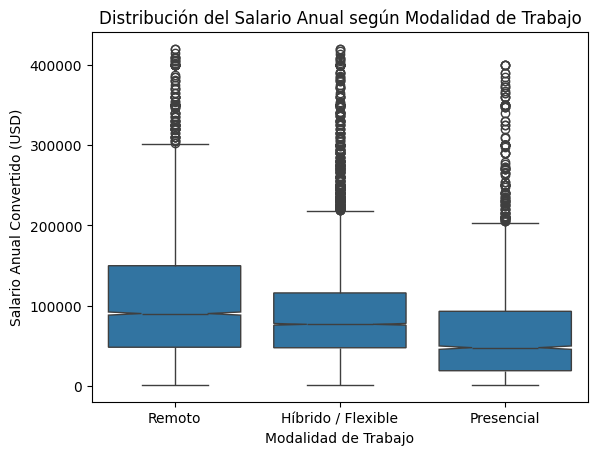

In [25]:
sns.boxplot(x='RemoteWork', y='ConvertedCompYearly', data=df_hbiv, notch=True)
plt.title('Distribución del Salario Anual según Modalidad de Trabajo')
plt.xlabel('Modalidad de Trabajo')
plt.ylabel('Salario Anual Convertido (USD)')
plt.show()

**Prueba Estadística (Kruskal-Wallis)**

Antes de elegir el test verificamos con Shapiro-Wilk si el salario es normal en cada modalidad (celda siguiente). Como no lo es en ninguna (p ≈ 0) y además la distribución es muy asimétrica, no corresponde un ANOVA y empleamos el **test no paramétrico de Kruskal-Wallis**, que evalúa si existen diferencias estadísticamente significativas entre las medianas de los tres grupos independientes.

In [26]:
# Verificamos la normalidad del salario en cada modalidad (Shapiro-Wilk sobre hasta 5.000 casos por grupo)
for grupo in medianas.index:
    salarios_grupo = df_hbiv.loc[df_hbiv["RemoteWork"] == grupo, "ConvertedCompYearly"]
    muestra = salarios_grupo.sample(min(len(salarios_grupo), 5000), random_state=42)
    w, p = stats.shapiro(muestra)
    print(f"{grupo}: Shapiro-Wilk p-valor = {p:.2e}")

Remoto: Shapiro-Wilk p-valor = 4.31e-42
Híbrido / Flexible: Shapiro-Wilk p-valor = 2.64e-51
Presencial: Shapiro-Wilk p-valor = 1.74e-49


In [27]:
# Preparar los grupos de datos
datos_por_modalidad = [df_hbiv[df_hbiv['RemoteWork'] == grupo]['ConvertedCompYearly'] for grupo in medianas.index]

# Test de Kruskal-Wallis
h_stat, p_valor = stats.kruskal(*datos_por_modalidad)

print(f"--- Resultados Test de Kruskal-Wallis ---")
print(f"Estadístico H: {h_stat:.2f}")
print(f"p-valor: {p_valor:.2e}")

--- Resultados Test de Kruskal-Wallis ---
Estadístico H: 817.45
p-valor: 3.12e-178


**Análisis post-hoc (prueba de Mann-Whitney U)**

Como el test de Kruskal-Wallis rechazó la hipótesis nula, sabemos que al menos una modalidad tiene una mediana salarial distinta. Para identificar qué pares difieren, comparamos las modalidades de a dos con la prueba de Mann-Whitney U, la alternativa no paramétrica para dos grupos independientes.

Como hacemos 3 comparaciones, aplicamos la **corrección de Bonferroni** (multiplicamos cada p-valor por 3) para no aumentar la probabilidad de error de tipo I. También calculamos el **tamaño del efecto** $\eta^2_H = \frac{H - k + 1}{n - k}$ (eta cuadrado basado en el estadístico $H$), que indica qué tan grande es la diferencia: 0,01 es pequeño, 0,06 moderado y 0,14 grande.

Por último, como la hipótesis afirma una dirección (remoto **mayor** que presencial), la verificamos con un test de Mann-Whitney **unilateral** entre esos dos grupos.

In [28]:
alfa = 0.05
k_hbiv = len(datos_por_modalidad)
n_hbiv = len(df_hbiv)
eta2_hbiv = (h_stat - k_hbiv + 1) / (n_hbiv - k_hbiv)
print(f"Tamaño del efecto: eta²_H = {eta2_hbiv:.4f}\n")

grupos = list(medianas.index)
pares = [(grupos[i], grupos[j]) for i in range(len(grupos)) for j in range(i + 1, len(grupos))]

resultados_posthoc = []
for g1, g2 in pares:
    d1 = df_hbiv[df_hbiv["RemoteWork"] == g1]["ConvertedCompYearly"]
    d2 = df_hbiv[df_hbiv["RemoteWork"] == g2]["ConvertedCompYearly"]
    u_stat, p_val = stats.mannwhitneyu(d1, d2)
    p_corregido = min(p_val * len(pares), 1)
    resultados_posthoc.append({
        "Comparación": f"{g1} vs {g2}",
        "Mediana 1": d1.median(),
        "Mediana 2": d2.median(),
        "p-valor corregido (Bonferroni)": p_corregido,
        "Significativo": p_corregido < alfa
    })

display(pd.DataFrame(resultados_posthoc))

# Test unilateral para la dirección planteada en la hipótesis
remoto = df_hbiv[df_hbiv["RemoteWork"] == "Remoto"]["ConvertedCompYearly"]
presencial = df_hbiv[df_hbiv["RemoteWork"] == "Presencial"]["ConvertedCompYearly"]
u_dir, p_dir = stats.mannwhitneyu(remoto, presencial, alternative="greater")
print(f"Mann-Whitney unilateral (Remoto > Presencial): p-valor = {p_dir:.2e}")

Tamaño del efecto: eta²_H = 0.0405



,Comparación,Mediana 1,Mediana 2,p-valor corregido (Bonferroni),Significativo
0,Remoto vs Híbrido / Flexible,90000.0,76570.0,6.980067e-34,True
1,Remoto vs Presencial,90000.0,47468.5,5.500471e-154,True
2,Híbrido / Flexible vs Presencial,76570.0,47468.5,2.145695e-117,True


Mann-Whitney unilateral (Remoto > Presencial): p-valor = 9.17e-155


**Control por país**

El salario depende mucho del país, y el trabajo remoto puede ser más común en países que pagan más. Para descartar que la diferencia se deba solo a eso, repetimos la comparación dentro de **Estados Unidos**, el país con más respuestas.

In [29]:
df_hbiv_eeuu = df_limpio.loc[
    df_limpio["Country"] == "United States of America",
    ["RemoteWork", "ConvertedCompYearly"]
].dropna().copy()
df_hbiv_eeuu["RemoteWork"] = df_hbiv_eeuu["RemoteWork"].map(mapeo_modalidad)

print("Observaciones de Estados Unidos:", len(df_hbiv_eeuu))
display(df_hbiv_eeuu.groupby("RemoteWork")["ConvertedCompYearly"].agg(["count", "median"]).round(0))

h_eeuu, p_eeuu = stats.kruskal(*[g["ConvertedCompYearly"] for _, g in df_hbiv_eeuu.groupby("RemoteWork")])
print(f"Kruskal-Wallis en Estados Unidos: H = {h_eeuu:.2f}, p-valor = {p_eeuu:.2e}")

Observaciones de Estados Unidos: 4525


,count,median
RemoteWork,,
Híbrido / Flexible,1742,143050.0
Presencial,682,105414.0
Remoto,2101,160272.0


Kruskal-Wallis en Estados Unidos: H = 261.28, p-valor = 1.84e-57


**Conclusión de la hipótesis B**

- **Descriptiva:** la mediana salarial es de **USD 90.000** en la modalidad remota, **USD 76.570** en la híbrida/flexible y **USD 47.468,5** en la presencial. El boxplot muestra que el centro de la distribución baja a medida que aumenta la presencialidad.
- **Kruskal-Wallis:** $H = 817{,}45$ con un p-valor de $3{,}12 \times 10^{-178}$, así que **se rechaza $H_0$**: las medianas difieren según la modalidad. El tamaño del efecto es $\eta^2_H = 0{,}041$, **pequeño** (está entre 0,01 y 0,06): aunque la diferencia de medianas es grande en dinero, dentro de cada modalidad hay mucha variación, sobre todo entre países.
- **Comparaciones de a pares (Mann-Whitney con Bonferroni):** las tres modalidades difieren entre sí. El test unilateral confirma la dirección planteada: el salario remoto es mayor que el presencial (p-valor = $9{,}17 \times 10^{-155}$).
- **Control por país:** dentro de Estados Unidos (4.525 respuestas) se repite el mismo orden: remoto USD 160.272, híbrido USD 143.050 y presencial USD 105.414 (Kruskal-Wallis, p-valor = $1{,}84 \times 10^{-57}$). La diferencia no se explica solo porque el trabajo remoto sea más común en países que pagan más.
- **Conclusión final:** la hipótesis **se confirma**. Quienes trabajan de forma remota perciben salarios significativamente mayores que quienes trabajan de forma presencial: casi el doble en la mediana global y un 52 % más dentro de Estados Unidos. Como es un estudio observacional, esto muestra una **asociación** y no una causa: por ejemplo, los puestos remotos podrían corresponder a perfiles más senior.

## C. Hipótesis multivariada

**Propuesta:** El salario anual convertido a una moneda común (ConvertedCompYearly) está asociado con la edad (Age), la experiencia profesional (WorkExp), el aprendizaje de herramientas de IA durante el último año (LearnCodeAI) y el máximo nivel educativo alcanzado (EdLevel).

- Age: la edad podría estar relacionada con el salario debido a diferencias en la trayectoria laboral y la experiencia acumulada.
- WorkExp: es razonable esperar que la experiencia profesional esté relacionada con la remuneración, ya que los trabajadores con mayor experiencia pueden acceder a puestos de mayor responsabilidad y mejor remuneración.
- LearnCodeAI: haber aprendido a usar herramientas de IA (o a programar para IA) podría estar relacionado con la actualización de conocimientos y la incorporación de nuevas tecnologías, características que podrían asociarse con determinadas oportunidades laborales.
- EdLevel: el nivel educativo alcanzado podría estar relacionado con el acceso a determinados puestos de trabajo y sus correspondientes remuneraciones.

Variable objetivo: `ConvertedCompYearly`

Variables explicativas: `Age, WorkExp, LearnCodeAI y EdLevel.`

De esta manera proponemos la siguiente hipótesis:
- H₀: no existe una asociación estadísticamente significativa entre el salario anual y el conjunto de variables explicativas consideradas.
- H₁: existe una asociación estadísticamente significativa entre el salario anual y al menos una de las variables explicativas consideradas.

Para el análisis de esta hipótesis proponemos utilizar un modelo de regresión lineal múltiple. La estructura del modelo sería:

$$\begin{aligned}
Salario ={}& \beta_0+\beta_1 Age+\beta_2 WorkExp\\
&+\beta_3 LearnCodeAI+\beta_4 EdLevel+\varepsilon
\end{aligned}$$

Primero revisamos las variables. Las cualitativas ya se codificaron numéricamente en la limpieza: `Age` en la sección 2.2.1, y `EdLevel` y `LearnCodeAI` en la sección 2.3 (de `LearnCodeAI` usamos la variable binaria `LearnCodeAI_Bin`).

In [30]:
variables_hmulti = [
    "ConvertedCompYearly",
    "Age",
    "WorkExp",
    "LearnCodeAI",
    "EdLevel"
]

# Información general
df_limpio[variables_hmulti].info()

# Cantidad y porcentaje de nulos
nulos = pd.DataFrame({
    "Nulos": df_limpio[variables_hmulti].isna().sum(),
    "% Nulos": df_limpio[variables_hmulti].isna().mean() * 100
})

display(nulos)

# Estadísticas de variables numéricas
display(
    df_limpio[["ConvertedCompYearly", "WorkExp"]].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

# Frecuencias de variables categóricas
for columna in ["Age", "LearnCodeAI", "EdLevel"]:
    print(f"\n--- {columna} ---")
    display(df_limpio[columna].value_counts(dropna=False))

# ¿Los nulos del salario son al azar? Porcentaje de personas sin salario según su situación laboral
sin_salario = df_limpio["ConvertedCompYearly"].isna().groupby(df_limpio["Employment"]).mean() * 100
display(sin_salario.sort_values().round(1).to_frame("% sin salario"))

<class 'pandas.DataFrame'>
Index: 47567 entries, 0 to 49190
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ConvertedCompYearly  22705 non-null  float64
 1   Age                  47206 non-null  float64
 2   WorkExp              47567 non-null  float64
 3   LearnCodeAI          43606 non-null  str    
 4   EdLevel              45898 non-null  float64
dtypes: float64(4), str(1)
memory usage: 2.2 MB


,Nulos,% Nulos
ConvertedCompYearly,24862,52.267328
Age,361,0.758930
WorkExp,0,0.000000
LearnCodeAI,3961,8.327202
EdLevel,1669,3.508735


,ConvertedCompYearly,WorkExp
count,22705.000000,47567.000000
mean,89749.140013,11.481300
std,68200.015705,10.647489
min,1000.000000,0.000000
1%,1665.000000,0.000000
25%,41765.000000,3.000000
50%,75744.000000,9.000000
75%,120267.000000,18.000000
95%,220000.000000,33.000000
99%,325047.000000,43.000000



--- Age ---


Age
34.0    16055
44.0    12843
24.0     8751
54.0     6092
64.0     2559
70.0      906
NaN       361
Name: count, dtype: int64


--- LearnCodeAI ---


LearnCodeAI
Yes, I learned how to use AI-enabled tools required for my job or to benefit my career                                15789
Yes, I learned how to use AI-enabled tools for my personal curiosity and/or hobbies                                   13542
No, I learned something that was not related to AI or AI enablement for my personal curiosity and/or hobbies           5099
No, I didn't spend time learning in the past year                                                                      4710
No, I learned something that was not related to AI or AI enablement as required for my job or to benefit my career     4466
NaN                                                                                                                    3961
Name: count, dtype: int64


--- EdLevel ---


EdLevel
5.0    19679
6.0    12272
3.0     5937
2.0     3451
7.0     2521
NaN     1669
4.0     1502
1.0      536
Name: count, dtype: int64

,% sin salario
Employment,
Employed,43.0
"Independent contractor, freelancer, or self-employed",55.7
Not employed,79.7
Retired,82.3
Student,86.1
I prefer not to say,91.9


Podemos observar que más de la mitad de las observaciones tienen nulos en ConvertedCompYearly. Como la cantidad es tan grande, consideramos que implementar cualquier tipo de relleno de datos en los mismos va a provocar un sesgo grande, el cual difícilmente represente correctamente la naturaleza real de la población.

Entendemos que eliminar por eliminar no es conveniente, ya que esta es solo 1 de las 172 variables originales. Si eliminásemos indiscriminadamente, nuestras observaciones se reducirían en un porcentaje demasiado grande. Por ende, decidimos eliminar todas las filas que tengan nulos en este campo solo para este análisis en particular. Para ello creamos un dataset aparte que nos servirá para trabajar sobre nuestra hipótesis.

Nuestra justificación para nuestra decisión es simple: una muestra más pequeña no necesariamente es un problema, una muestra sesgada sí puede serlo. Igualmente, los faltantes del salario no son completamente al azar: falta en el 86,1 % de los estudiantes y en el 79,7 % de las personas sin empleo, contra el 43,0 % de los empleados (última tabla de la celda anterior). Por eso los resultados describen a quienes sí informaron su salario.

In [31]:
variables_hmulti = [
    "ConvertedCompYearly",
    "Age",
    "WorkExp",
    "LearnCodeAI_Bin",
    "EdLevel"
]

# Crear el dataset específico, conservando salarios informados
df_hmulti = df_limpio.loc[
    df_limpio["ConvertedCompYearly"].notna(),
    variables_hmulti
].copy()

# Verificar dimensiones y estructura
print("Dimensiones de df_hmulti:", df_hmulti.shape)
df_hmulti.info()

# Cantidad y porcentaje de valores faltantes
faltantes = pd.DataFrame({
    "Cantidad": df_hmulti.isna().sum(),
    "Porcentaje": df_hmulti.isna().mean() * 100
})

display(faltantes)

Dimensiones de df_hmulti: (22705, 5)
<class 'pandas.DataFrame'>
Index: 22705 entries, 0 to 49122
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ConvertedCompYearly  22705 non-null  float64
 1   Age                  22689 non-null  float64
 2   WorkExp              22705 non-null  float64
 3   LearnCodeAI_Bin      22680 non-null  float64
 4   EdLevel              22502 non-null  float64
dtypes: float64(5)
memory usage: 1.0 MB


,Cantidad,Porcentaje
ConvertedCompYearly,0,0.000000
Age,16,0.070469
WorkExp,0,0.000000
LearnCodeAI_Bin,25,0.110108
EdLevel,203,0.894076


Eliminamos las observaciones que tienen nulo en Age, LearnCodeAI_Bin o EdLevel (Age todavía se usa en el análisis de correlaciones).

In [32]:
# Eliminar registros con valores faltantes en las variables del modelo
df_hmulti = df_hmulti.dropna().copy()

# Verificar resultados
print("Dimensiones después de la limpieza:", df_hmulti.shape)
print("Valores faltantes restantes:", df_hmulti.isna().sum().sum())

Dimensiones después de la limpieza: (22462, 5)
Valores faltantes restantes: 0


Revisamos la distribución de `ConvertedCompYearly`, sus posibles valores atípicos y si conviene transformarla.

count     22462.000000
mean      89931.878818
std       68262.739081
min        1000.000000
25%       41765.000000
50%       76239.000000
75%      120616.500000
max      420000.000000
Name: ConvertedCompYearly, dtype: float64

Asimetría: 1.3338071757453536


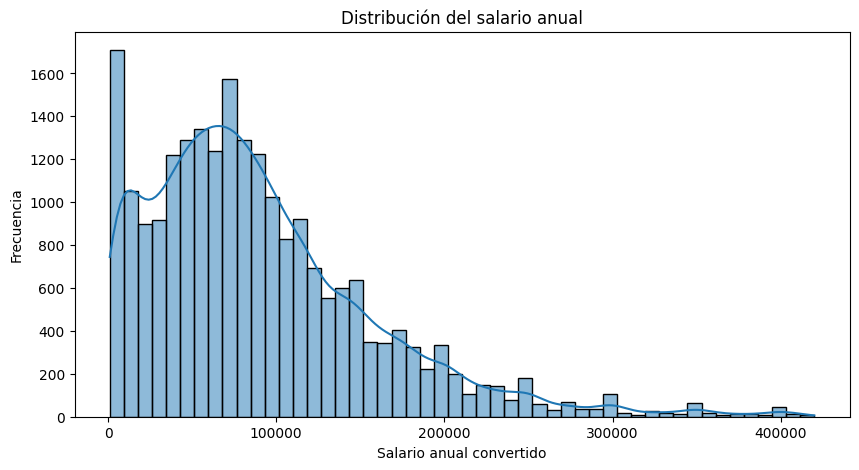

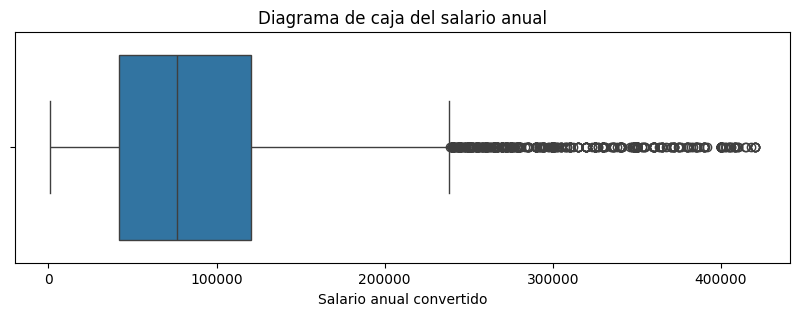

In [33]:
# Estadísticas descriptivas
display(df_hmulti["ConvertedCompYearly"].describe())

# Asimetría de la distribución
print("Asimetría:", df_hmulti["ConvertedCompYearly"].skew())

# Histograma
plt.figure(figsize=(10, 5))
sns.histplot(data=df_hmulti, x="ConvertedCompYearly", bins=50, kde=True)
plt.title("Distribución del salario anual")
plt.xlabel("Salario anual convertido")
plt.ylabel("Frecuencia")
plt.show()

# Diagrama de caja
plt.figure(figsize=(10, 3))
sns.boxplot(data=df_hmulti, x="ConvertedCompYearly")
plt.title("Diagrama de caja del salario anual")
plt.xlabel("Salario anual convertido")
plt.show()

Podemos observar que la distribución está sesgada a derecha (asimetría de 1,33). Probamos una transformación logarítmica, que comprime los salarios altos.

,ConvertedCompYearly,LogSalary
count,22462.000000,22462.000000
mean,89931.878818,11.015765
std,68262.739081,1.072037
min,1000.000000,6.907755
25%,41765.000000,10.639814
50%,76239.000000,11.241628
75%,120616.500000,11.700371
max,420000.000000,12.948010


Asimetría original: 1.3338071757453536
Asimetría transformada: -1.3360452500661153
Salarios menores a 10.000 USD: 7.9 %


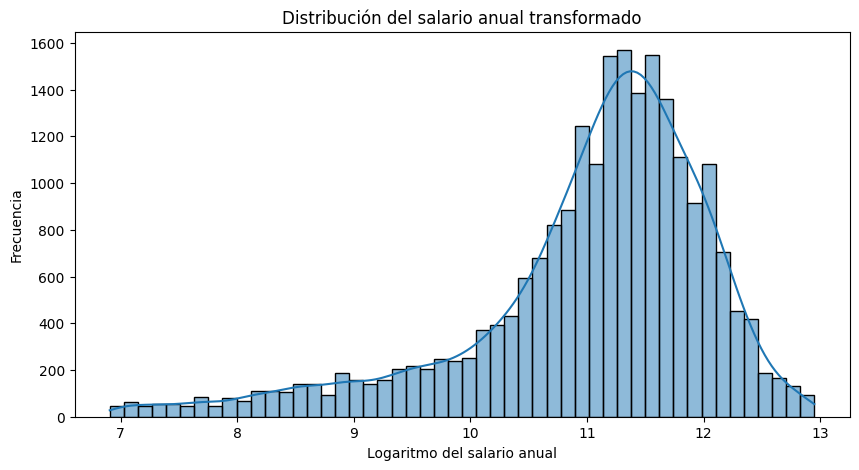

In [34]:
# Aplicar transformación logarítmica al salario
df_hmulti["LogSalary"] = np.log(df_hmulti["ConvertedCompYearly"])

# Comparar estadísticas y asimetría
display(df_hmulti[["ConvertedCompYearly", "LogSalary"]].describe())

print("Asimetría original:", df_hmulti["ConvertedCompYearly"].skew())
print("Asimetría transformada:", df_hmulti["LogSalary"].skew())
print(f"Salarios menores a 10.000 USD: {(df_hmulti['ConvertedCompYearly'] < 10000).mean() * 100:.1f} %")

plt.figure(figsize=(10, 5))
sns.histplot(data=df_hmulti, x="LogSalary", bins=50, kde=True)
plt.title("Distribución del salario anual transformado")
plt.xlabel("Logaritmo del salario anual")
plt.ylabel("Frecuencia")
plt.show()

La transformación no elimina la asimetría, sino que la invierte: pasa de 1,33 (cola a la derecha) a −1,34 (cola a la izquierda). El logaritmo comprime los salarios altos, pero estira los más bajos, y en la base hay muchos salarios bajos en dólares (el 7,9 % es menor a 10.000 USD).

Aun así, usamos el logaritmo del salario como variable dependiente del modelo por dos motivos:

- Los salarios suelen variar en forma proporcional: por ejemplo, un año más de experiencia se asocia con un salario un cierto porcentaje mayor, no con una cantidad fija de dólares. Con el logaritmo, cada coeficiente se interpreta directamente como un cambio porcentual.
- Evita que los salarios más altos dominen el ajuste.

La cola izquierda vuelve a aparecer al revisar la normalidad de los residuos del modelo.

,ConvertedCompYearly,Age,WorkExp,LearnCodeAI_Bin,EdLevel
ConvertedCompYearly,1.000000,0.394163,0.459397,0.044699,0.110812
Age,0.394163,1.000000,0.857573,0.011115,0.135750
WorkExp,0.459397,0.857573,1.000000,0.027122,0.086018
LearnCodeAI_Bin,0.044699,0.011115,0.027122,1.000000,0.022801
EdLevel,0.110812,0.135750,0.086018,0.022801,1.000000


Spearman Age - salario: rho = 0.39, p-valor = 0.00e+00


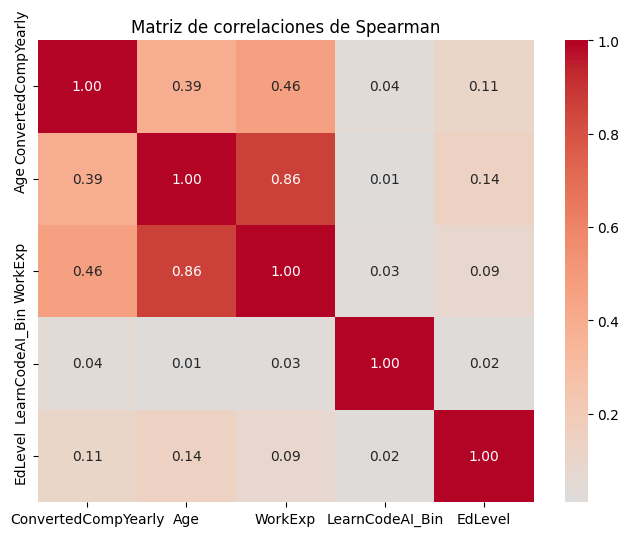

In [35]:
variables_correlacion = [
    "ConvertedCompYearly",
    "Age",
    "WorkExp",
    "LearnCodeAI_Bin",
    "EdLevel"
]

correlaciones = df_hmulti[variables_correlacion].corr(method="spearman")

display(correlaciones)

# Significancia de la correlación entre la edad y el salario
rho_edad, p_edad = stats.spearmanr(df_hmulti["Age"], df_hmulti["ConvertedCompYearly"])
print(f"Spearman Age - salario: rho = {rho_edad:.2f}, p-valor = {p_edad:.2e}")

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Matriz de correlaciones de Spearman")
plt.show()

Observamos que WorkExp y Age tienen una correlación muy alta (0,86), lo cual tiene sentido: una persona de más edad tiene mayores oportunidades de acumular más experiencia laboral. Incluir las dos en el modelo generaría multicolinealidad. Por esto, decidimos descartar la variable `Age` y conservar WorkExp, que además está más correlacionada con el salario (0,46 contra 0,39 de Age). La correlación de Age con el salario es significativa (p ≈ 0), así que la edad también se asocia con el salario, pero no la incluimos en el modelo para evitar la multicolinealidad.

#### Ajuste del modelo de regresión lineal múltiple

Como `Age` y `WorkExp` están muy correlacionadas, dejamos `Age` afuera y ajustamos el modelo con las tres variables restantes. Usamos el logaritmo del salario como variable dependiente, por los motivos explicados más arriba:

$$\log(Salario) = \beta_0 + \beta_1 \, WorkExp + \beta_2 \, LearnCodeAI\_Bin + \beta_3 \, EdLevel + \varepsilon$$

El modelo se estima por mínimos cuadrados ordinarios (OLS), con $\alpha = 0{,}05$:

- **Test F (modelo global):** $H_0$: $\beta_1 = \beta_2 = \beta_3 = 0$; $H_1$: al menos un $\beta_j \neq 0$.
- **Test t (cada coeficiente):** $H_0$: $\beta_j = 0$; $H_1$: $\beta_j \neq 0$.

`EdLevel` se usa con la codificación ordinal de 1 a 7 definida en la limpieza, lo que supone que la distancia entre niveles educativos es la misma.

In [36]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

variables_modelo = ["WorkExp", "LearnCodeAI_Bin", "EdLevel"]

X_hmulti = sm.add_constant(df_hmulti[variables_modelo])
y_hmulti = df_hmulti["LogSalary"]

modelo_hmulti = sm.OLS(y_hmulti, X_hmulti).fit()
print(modelo_hmulti.summary())

                            OLS Regression Results                            
Dep. Variable:              LogSalary   R-squared:                       0.152
Model:                            OLS   Adj. R-squared:                  0.152
Method:                 Least Squares   F-statistic:                     1339.
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        21:25:26   Log-Likelihood:                -31586.
No. Observations:               22462   AIC:                         6.318e+04
Df Residuals:                   22458   BIC:                         6.321e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               9.9757      0.030    3

In [37]:
# Efecto de cada variable sobre el salario, en porcentaje: (e^beta - 1) * 100
efectos_hmulti = pd.DataFrame({
    "Coeficiente": modelo_hmulti.params[variables_modelo],
    "Efecto sobre el salario (%)": (np.exp(modelo_hmulti.params[variables_modelo]) - 1) * 100,
    "p-valor": modelo_hmulti.pvalues[variables_modelo]
})
display(efectos_hmulti.round(4))

print(f"R² = {modelo_hmulti.rsquared:.4f}   R² ajustado = {modelo_hmulti.rsquared_adj:.4f}")
print(f"Test F: F = {modelo_hmulti.fvalue:.2f}, p-valor = {modelo_hmulti.f_pvalue:.2e}")

,Coeficiente,Efecto sobre el salario (%),p-valor
WorkExp,0.0395,4.0338,0.0000
LearnCodeAI_Bin,0.0382,3.8974,0.0075
EdLevel,0.0972,10.2043,0.0000


R² = 0.1517   R² ajustado = 0.1516
Test F: F = 1338.81, p-valor = 0.00e+00


#### Verificación de los supuestos del modelo

Revisamos los supuestos de la regresión lineal vistos en clase:

- **Normalidad de los residuos:** QQ-plot y test de Shapiro-Wilk (sobre una muestra de 5.000 residuos, porque con más casos el test pierde precisión).
- **Homocedasticidad:** gráfico de residuos contra valores predichos; no debería verse una forma de cono ni una tendencia.
- **Multicolinealidad:** factor de inflación de la varianza (VIF); valores menores a 5 indican que no hay un problema.

Si la varianza de los residuos no resulta constante, los p-valores del modelo pueden ser poco confiables. En ese caso los recalculamos con **errores estándar robustos (HC3)**, que no necesitan ese supuesto.

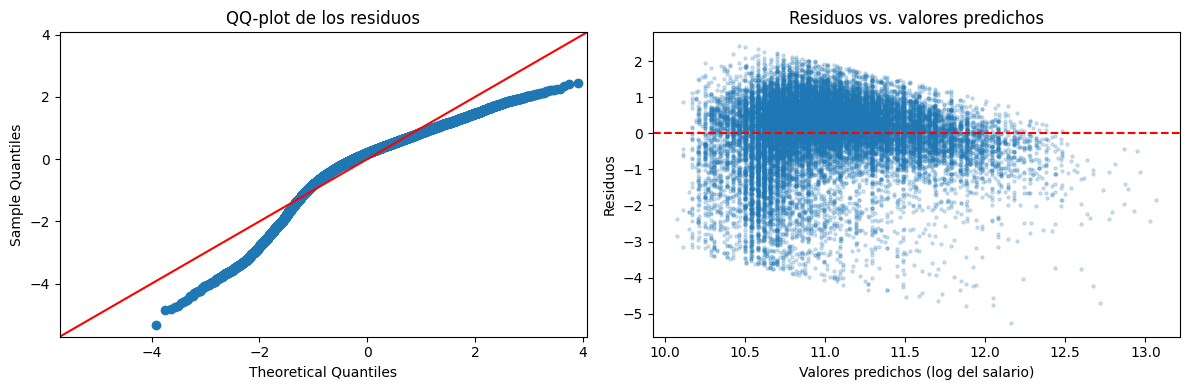

Shapiro-Wilk sobre los residuos: W = 0.9239, p-valor = 1.01e-44


,Variable,VIF
0,WorkExp,1.0
1,LearnCodeAI_Bin,1.0
2,EdLevel,1.0


,p-valor (OLS),p-valor (errores robustos HC3)
WorkExp,0.0000,0.0000
LearnCodeAI_Bin,0.0075,0.0064
EdLevel,0.0000,0.0000


In [38]:
residuos_hmulti = modelo_hmulti.resid
predichos_hmulti = modelo_hmulti.fittedvalues

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sm.qqplot(residuos_hmulti, line="45", fit=True, ax=ejes[0])
ejes[0].set_title("QQ-plot de los residuos")
ejes[1].scatter(predichos_hmulti, residuos_hmulti, alpha=0.2, s=5)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set_xlabel("Valores predichos (log del salario)")
ejes[1].set_ylabel("Residuos")
ejes[1].set_title("Residuos vs. valores predichos")
plt.tight_layout()
plt.show()

w_res, p_res = stats.shapiro(residuos_hmulti.sample(5000, random_state=42))
print(f"Shapiro-Wilk sobre los residuos: W = {w_res:.4f}, p-valor = {p_res:.2e}")

vif_hmulti = pd.DataFrame({
    "Variable": variables_modelo,
    "VIF": [variance_inflation_factor(X_hmulti.values, i + 1) for i in range(len(variables_modelo))]
})
display(vif_hmulti.round(2))

# Como la varianza de los residuos no es constante, revisamos los p-valores con errores estándar robustos (HC3)
modelo_robusto = sm.OLS(y_hmulti, X_hmulti).fit(cov_type="HC3")
display(pd.DataFrame({
    "p-valor (OLS)": modelo_hmulti.pvalues[variables_modelo],
    "p-valor (errores robustos HC3)": modelo_robusto.pvalues[variables_modelo]
}).round(4))

**Resultado del modelo**

- **Test F:** $F = 1.338{,}81$ con un p-valor prácticamente 0, así que **se rechaza $H_0$**: al menos una de las variables se asocia con el salario.
- **Coeficientes:** los tres son positivos y significativos ($\alpha = 0{,}05$). Como la variable dependiente es el logaritmo del salario, cada coeficiente se interpreta como un cambio porcentual, $(e^{\beta} - 1) \times 100$:
    - `WorkExp`: cada año de experiencia se asocia con un salario **4,0 % mayor** (p ≈ 0).
    - `LearnCodeAI_Bin`: haber aprendido herramientas de IA en el último año se asocia con un salario **3,9 % mayor** (p = 0,0075).
    - `EdLevel`: cada nivel educativo adicional se asocia con un salario **10,2 % mayor** (p ≈ 0).
- **Bondad del ajuste:** $R^2 = 0{,}152$. El modelo explica solo el **15 %** de la variabilidad del salario.

**Supuestos**

- **Normalidad:** Shapiro-Wilk da un p-valor prácticamente 0 y el QQ-plot muestra una cola izquierda más larga que la de una normal, así que **no se cumple**. Igualmente, con 22.462 observaciones los tests t y F siguen siendo aproximadamente válidos por el teorema central del límite.
- **Homocedasticidad:** en el gráfico de residuos la dispersión es menor para los salarios predichos más altos, así que **la varianza no es constante**. Por eso recalculamos los p-valores con errores robustos (HC3): los tres coeficientes siguen siendo significativos (`LearnCodeAI_Bin` pasa de 0,0075 a 0,0064; los otros dos siguen en 0).
- **Multicolinealidad:** los VIF son cercanos a 1, así que **no hay problema**. Esto confirma que fue correcto sacar `Age`, que estaba muy correlacionada con `WorkExp`.

**Peso del país de residencia**

El país no forma parte de la hipótesis, pero define en gran parte el salario en dólares. Para tener una referencia, ajustamos una regresión del logaritmo del salario usando solo el país (una variable indicadora por país) y comparamos su $R^2$ con el del modelo.

In [39]:
# R² de un modelo que usa solo el país de residencia (una variable indicadora por país)
paises_hmulti = df_limpio.loc[df_hmulti.index, "Country"]
X_pais = sm.add_constant(pd.get_dummies(paises_hmulti, drop_first=True, dtype=float))
modelo_pais = sm.OLS(df_hmulti["LogSalary"], X_pais).fit()

print("Cantidad de países:", paises_hmulti.nunique())
print(f"R² solo con el país: {modelo_pais.rsquared:.3f}")
print(f"R² del modelo con WorkExp, LearnCodeAI_Bin y EdLevel: {modelo_hmulti.rsquared:.3f}")

Cantidad de países: 159
R² solo con el país: 0.429
R² del modelo con WorkExp, LearnCodeAI_Bin y EdLevel: 0.152


**Conclusión de la hipótesis C**

La hipótesis **se confirma**: la experiencia profesional, el aprendizaje de herramientas de IA y el nivel educativo se asocian significativamente con el salario, las tres en el sentido esperado. La edad también se asocia con el salario (ρ de Spearman = 0,39, p ≈ 0), pero no se incluyó en el modelo porque está muy correlacionada con la experiencia (0,86). La experiencia y la educación son las que más influyen; el efecto de haber aprendido IA es más chico.

Sin embargo, el modelo explica solo el 15 % de la variabilidad del salario. Gran parte del resto depende del **país de residencia**, que no forma parte de la hipótesis: por sí solo, el país explica el 43 % de la variabilidad del logaritmo del salario. Además, como los residuos no son normales ni tienen varianza constante, los resultados deben leerse con cautela, aunque se mantienen con errores robustos.

# 4. Validación de las hipótesis propuestas por la cátedra

## a) Los desarrolladores que respondieron la encuesta de Argentina tienen un salario 3 veces mayor al Salario Mínimo, Vital y Móvil (SMVM)

**Interpretación:** entendemos "3 veces mayor" como que el salario anual de los desarrolladores de Argentina es **al menos 3 veces** el SMVM anual. Como los salarios son asimétricos, trabajamos con la **mediana**.

**Variables:** `Country` (para quedarnos con Argentina) y `ConvertedCompYearly`. Según los metadatos de la encuesta, este salario es la remuneración **anual total** (sueldo, bonos y beneficios, antes de impuestos), convertida a dólares.

**Valor del SMVM:** la encuesta se realizó entre el 29 de mayo y el 23 de junio de 2025. El SMVM vigente desde el 1° de junio de 2025 era de **$313.400 mensuales** (Resolución 5/2025 del Consejo Nacional del Empleo, la Productividad y el Salario Mínimo, Vital y Móvil).

**Conversión a dólares anuales:**
- Como el salario de la encuesta es anual e incluye bonificaciones, anualizamos el SMVM con **13 sueldos** (12 meses más el aguinaldo).
- Para pasar a dólares usamos **el mismo tipo de cambio que aplicó Stack Overflow**. Lo obtenemos de los propios datos, dividiendo el salario en pesos (`CompTotal`) por el salario convertido (`ConvertedCompYearly`) en los argentinos que respondieron en pesos. Usamos `df` porque `CompTotal` se eliminó en la limpieza.

**Hipótesis** (con $Me$ = mediana del salario anual y $U$ = 3 × SMVM anual en dólares):
- $H_0$: $Me \leq U$
- $H_1$: $Me > U$

**Técnica:** primero verificamos la normalidad con Shapiro-Wilk. Si no se cumple, usamos el **test de Wilcoxon para una muestra** (unilateral), la alternativa no paramétrica al test t para una media. Como complemento aplicamos la **prueba del signo**, que compara la proporción de salarios por encima del umbral con 0,5. Esta segunda prueba es importante porque el test de Wilcoxon supone que la distribución es aproximadamente simétrica, y los salarios no lo son; la prueba del signo no necesita ese supuesto. Nivel de significancia $\alpha = 0{,}05$.

In [40]:
smvm_junio_2025 = 313400    # pesos por mes (Resolución 5/2025)
sueldos_por_anio = 13       # 12 sueldos + aguinaldo

# Tipo de cambio que usó Stack Overflow: salario en pesos / salario convertido a dólares
argentinos_en_pesos = df[
    (df["Country"] == "Argentina") &
    (df["Currency"].astype(str).str.startswith("ARS")) &
    (df["ConvertedCompYearly"].notna())
]
cociente = argentinos_en_pesos["CompTotal"] / argentinos_en_pesos["ConvertedCompYearly"]
tipo_cambio = cociente.median()

smvm_anual_usd = smvm_junio_2025 * sueldos_por_anio / tipo_cambio
umbral_usd = 3 * smvm_anual_usd

print(f"Respuestas de Argentina en pesos: {len(argentinos_en_pesos)}")
print(f"Tipo de cambio implícito: {tipo_cambio:,.2f} ARS por USD (mínimo {cociente.min():,.2f}, máximo {cociente.max():,.2f})")
print(f"SMVM anual: {smvm_anual_usd:,.0f} USD")
print(f"Umbral (3 x SMVM anual): {umbral_usd:,.0f} USD")

Respuestas de Argentina en pesos: 90
Tipo de cambio implícito: 1,172.26 ARS por USD (mínimo 1,153.85, máximo 1,200.00)
SMVM anual: 3,476 USD
Umbral (3 x SMVM anual): 10,427 USD


Desarrolladores de Argentina con salario informado: 145


,ConvertedCompYearly
count,145.0
mean,50223.0
std,34927.0
min,1200.0
25%,22521.0
50%,42653.0
75%,75000.0
max,153550.0


Shapiro-Wilk: W = 0.9441, p-valor = 1.51e-05


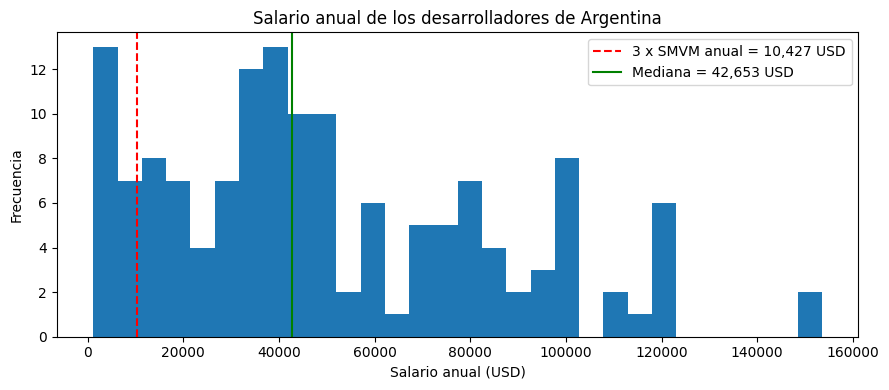

In [41]:
salarios_ar = df_limpio.loc[df_limpio["Country"] == "Argentina", "ConvertedCompYearly"].dropna()
print("Desarrolladores de Argentina con salario informado:", len(salarios_ar))
display(salarios_ar.describe().round(0).to_frame())

w_ar, p_ar = stats.shapiro(salarios_ar)
print(f"Shapiro-Wilk: W = {w_ar:.4f}, p-valor = {p_ar:.2e}")

plt.figure(figsize=(9, 4))
plt.hist(salarios_ar, bins=30)
plt.axvline(umbral_usd, color="red", linestyle="--", label=f"3 x SMVM anual = {umbral_usd:,.0f} USD")
plt.axvline(salarios_ar.median(), color="green", label=f"Mediana = {salarios_ar.median():,.0f} USD")
plt.title("Salario anual de los desarrolladores de Argentina")
plt.xlabel("Salario anual (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
# Test de Wilcoxon para una muestra, unilateral: ¿la mediana supera el umbral?
w_stat_ar, p_wilcoxon_ar = stats.wilcoxon(salarios_ar - umbral_usd, alternative="greater")

# Prueba del signo: ¿más de la mitad de los salarios supera el umbral?
por_encima = (salarios_ar > umbral_usd).sum()
p_signo_ar = stats.binomtest(int(por_encima), n=len(salarios_ar), p=0.5, alternative="greater").pvalue

print(f"Wilcoxon: estadístico = {w_stat_ar:.1f}, p-valor = {p_wilcoxon_ar:.2e}")
print(f"Salarios por encima del umbral: {por_encima} de {len(salarios_ar)} ({por_encima / len(salarios_ar) * 100:.1f} %)")
print(f"Prueba del signo: p-valor = {p_signo_ar:.2e}")
print(f"La mediana equivale a {salarios_ar.median() / smvm_anual_usd:.1f} veces el SMVM anual")

# Sensibilidad: el mismo cálculo sin aguinaldo (12 sueldos)
umbral_12 = 3 * smvm_junio_2025 * 12 / tipo_cambio
print(f"\nSin aguinaldo: umbral = {umbral_12:,.0f} USD; por encima: {(salarios_ar > umbral_12).mean() * 100:.1f} %")

Wilcoxon: estadístico = 10261.0, p-valor = 5.25e-23
Salarios por encima del umbral: 126 de 145 (86.9 %)
Prueba del signo: p-valor = 7.34e-21
La mediana equivale a 12.3 veces el SMVM anual

Sin aguinaldo: umbral = 9,625 USD; por encima: 88.3 %


**Resultado**

- El tipo de cambio que usó Stack Overflow es de **1.172,26 pesos por dólar** (la mediana del cociente, que casi no varía entre las 90 respuestas en pesos: va de 1.153,85 a 1.200). Con ese valor, el SMVM anual equivale a **USD 3.476**, y el umbral de 3 × SMVM a **USD 10.427**.
- Hay **145** desarrolladores de Argentina con salario informado. Su mediana es de **USD 42.653**.
- Shapiro-Wilk da un p-valor de $1{,}51 \times 10^{-5}$: los salarios **no son normales**, así que usamos el test de Wilcoxon.
- **Wilcoxon (unilateral):** p-valor = $5{,}25 \times 10^{-23}$, así que **se rechaza $H_0$**.
- **Prueba del signo:** 126 de los 145 salarios (86,9 %) superan el umbral, con un p-valor de $7{,}34 \times 10^{-21}$. Como no supone simetría (y los salarios son asimétricos: la media, USD 50.223, supera a la mediana), confirma el resultado de Wilcoxon.
- La mediana equivale a **12,3 veces** el SMVM anual, muy por encima de 3 veces.
- Si se anualiza sin aguinaldo (12 sueldos), el umbral baja a USD 9.625 y lo supera el 88,3 %, así que la conclusión no cambia.

**Conclusión de la hipótesis a)**

La hipótesis **se confirma**: el salario de los desarrolladores de Argentina que respondieron la encuesta supera ampliamente 3 veces el SMVM. Hay que tener en cuenta tres limitaciones:

- La muestra es chica (145 personas) y voluntaria. Quienes responden una encuesta en inglés de Stack Overflow pueden tener más acceso a trabajos para el exterior pagados en dólares, así que no representan necesariamente a todos los desarrolladores del país.
- El resultado depende del tipo de cambio usado para pasar el SMVM a dólares.
- Un 13 % de los encuestados (19 personas) no llega al umbral.

## b) Los años de experiencia profesional influyen en la confianza en la precisión de las herramientas de IA


**Propuesta:** Los años de experiencia profesional influyen en la confianza en la precisión de las herramientas de IA.

**Justificación:** Es posible que los desarrolladores con más años de experiencia, al conocer a fondo los fundamentos del desarrollo y haber enfrentado múltiples problemas complejos, sean más escépticos respecto a la precisión del código generado por IA. Por el contrario, los perfiles más junior podrían depositar mayor confianza en estas herramientas.

**Variables utilizadas:**
*   `WorkExp`: Años de experiencia profesional (cuantitativa).
*   `AIAcc`: Nivel de confianza en la precisión de los resultados de IA (cualitativa ordinal).

**Hipótesis Estadísticas:**
*   $H_0$: Las medianas de los años de experiencia son iguales en todos los niveles de confianza en la IA.
*   $H_1$: Al menos un nivel de confianza presenta una mediana de años de experiencia distinta a los demás.

**1. Preparación de los datos y estadística descriptiva**

Aislamos las variables `WorkExp` y `AIAcc`, eliminamos los valores nulos para este análisis y calculamos la mediana de años de experiencia para cada nivel de confianza.

In [43]:
# Aislamos variables y eliminamos nulos
df_ia = df_limpio[['WorkExp', 'AIAcc']].dropna().copy()

mapeo_ia = {
    'Highly distrust': 'Desconfía mucho',
    'Somewhat distrust': 'Desconfía algo',
    'Neither trust nor distrust': 'Neutral',
    'Somewhat trust': 'Confía algo',
    'Highly trust': 'Confía mucho'
}
df_ia['AIAcc'] = df_ia['AIAcc'].map(lambda x: mapeo_ia.get(x, x))

orden_confianza = [
    'Desconfía mucho',
    'Desconfía algo',
    'Neutral',
    'Confía algo',
    'Confía mucho'
]

print(f"Observaciones válidas para este análisis: {len(df_ia)}\n")

# Calculamos y mostramos las medianas de experiencia por nivel de confianza
resumen_ia = df_ia.groupby('AIAcc')['WorkExp'].agg(['count', 'median', 'mean']).reindex(orden_confianza)
print("Estadísticas de años de experiencia según nivel de confianza en IA:")
display(resumen_ia.round(2))

Observaciones válidas para este análisis: 31993

Estadísticas de años de experiencia según nivel de confianza en IA:


,count,median,mean
AIAcc,,,
Desconfía mucho,6244,10.0,13.14
Desconfía algo,8454,10.0,13.08
Neutral,6907,10.0,13.12
Confía algo,9470,10.0,12.58
Confía mucho,918,9.0,11.46


**2. Visualización de las distribuciones**

Para tener un panorama más claro, generamos un diagrama de caja (*boxplot*). Esto nos permitirá visualizar gráficamente cómo se distribuye la experiencia laboral en cada uno de los niveles de confianza declarados por los encuestados.

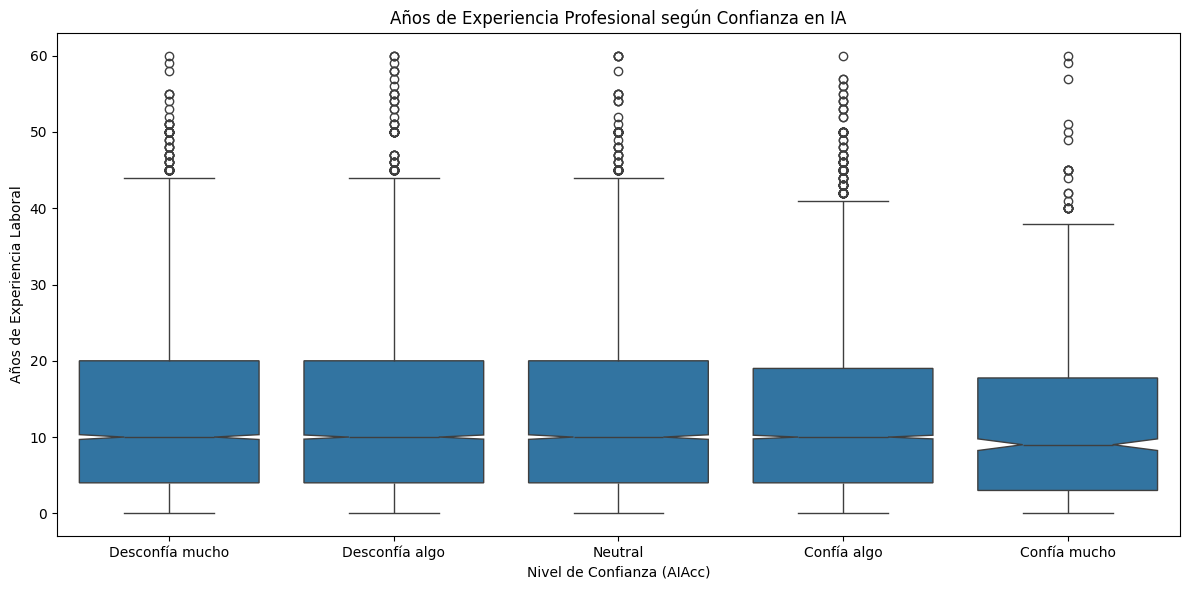

In [44]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='AIAcc', y='WorkExp', data=df_ia, order=orden_confianza, notch=True)
plt.title('Años de Experiencia Profesional según Confianza en IA')
plt.xlabel('Nivel de Confianza (AIAcc)')
plt.ylabel('Años de Experiencia Laboral')
plt.tight_layout()
plt.show()

**3. Elección de la técnica**

`WorkExp` es una variable cuantitativa y `AIAcc` es ordinal, con 5 niveles. Para saber si la experiencia cambia según el nivel de confianza en la IA, comparamos la distribución de `WorkExp` entre esos 5 grupos independientes.

Primero revisamos la normalidad de `WorkExp` en cada grupo con Shapiro-Wilk. Si no se cumple, no corresponde un ANOVA y usamos su alternativa no paramétrica, el **test de Kruskal-Wallis**, con $\alpha = 0{,}05$. Como la muestra es muy grande, también calculamos el **tamaño del efecto** $\eta^2_H$ (0,01 pequeño, 0,06 moderado, 0,14 grande).

Además, como las dos variables tienen un orden, medimos la **correlación de Spearman** entre la experiencia y el nivel de confianza (codificado de 1 = desconfía mucho a 5 = confía mucho). Indica si a más experiencia hay más (o menos) confianza.

Nota: en la limpieza, los valores vacíos de `WorkExp` se completaron con 0, porque la encuesta pedía dejar el campo vacío cuando la experiencia era 0.

In [45]:
# Normalidad de WorkExp en cada nivel de confianza
for nivel in orden_confianza:
    datos_nivel = df_ia.loc[df_ia["AIAcc"] == nivel, "WorkExp"]
    muestra = datos_nivel.sample(min(len(datos_nivel), 5000), random_state=42)
    w, p = stats.shapiro(muestra)
    print(f"{nivel:16s} n = {len(datos_nivel):5d}   Shapiro-Wilk p-valor = {p:.2e}")

# Test de Kruskal-Wallis
grupos_ia = [df_ia.loc[df_ia["AIAcc"] == nivel, "WorkExp"] for nivel in orden_confianza]
h_ia, p_ia = stats.kruskal(*grupos_ia)
k_ia = len(grupos_ia)
eta2_ia = (h_ia - k_ia + 1) / (len(df_ia) - k_ia)

print(f"\nKruskal-Wallis: H = {h_ia:.2f}, p-valor = {p_ia:.2e}")
print(f"Tamaño del efecto: eta²_H = {eta2_ia:.4f}")

Desconfía mucho  n =  6244   Shapiro-Wilk p-valor = 3.67e-46
Desconfía algo   n =  8454   Shapiro-Wilk p-valor = 1.49e-46
Neutral          n =  6907   Shapiro-Wilk p-valor = 4.77e-47
Confía algo      n =  9470   Shapiro-Wilk p-valor = 2.05e-46
Confía mucho     n =   918   Shapiro-Wilk p-valor = 1.78e-25



Kruskal-Wallis: H = 32.00, p-valor = 1.92e-06
Tamaño del efecto: eta²_H = 0.0009


In [46]:
# Comparaciones de a pares con corrección de Bonferroni (10 comparaciones)
pares_ia = [(orden_confianza[i], orden_confianza[j])
            for i in range(len(orden_confianza)) for j in range(i + 1, len(orden_confianza))]

resultados_ia = []
for g1, g2 in pares_ia:
    d1 = df_ia.loc[df_ia["AIAcc"] == g1, "WorkExp"]
    d2 = df_ia.loc[df_ia["AIAcc"] == g2, "WorkExp"]
    u, p = stats.mannwhitneyu(d1, d2)
    p_corregido = min(p * len(pares_ia), 1)
    resultados_ia.append({
        "Comparación": f"{g1} vs {g2}",
        "Mediana 1": d1.median(),
        "Mediana 2": d2.median(),
        "p-valor corregido (Bonferroni)": p_corregido,
        "Significativo": p_corregido < 0.05
    })
display(pd.DataFrame(resultados_ia))

# Correlación de Spearman entre experiencia y nivel de confianza
codigo_confianza = df_ia["AIAcc"].map({nivel: i + 1 for i, nivel in enumerate(orden_confianza)})
rho_ia, p_rho_ia = stats.spearmanr(df_ia["WorkExp"], codigo_confianza)
print(f"Correlación de Spearman: rho = {rho_ia:.4f}, p-valor = {p_rho_ia:.2e}")

,Comparación,Mediana 1,Mediana 2,p-valor corregido (Bonferroni),Significativo
0,Desconfía mucho vs Desconfía algo,10.0,10.0,1.000000,False
1,Desconfía mucho vs Neutral,10.0,10.0,1.000000,False
2,Desconfía mucho vs Confía algo,10.0,10.0,0.234989,False
3,Desconfía mucho vs Confía mucho,10.0,9.0,0.000015,True
4,Desconfía algo vs Neutral,10.0,10.0,1.000000,False
5,Desconfía algo vs Confía algo,10.0,10.0,0.228419,False
6,Desconfía algo vs Confía mucho,10.0,9.0,0.000013,True
7,Neutral vs Confía algo,10.0,10.0,0.122698,False
8,Neutral vs Confía mucho,10.0,9.0,0.000006,True
9,Confía algo vs Confía mucho,10.0,9.0,0.000678,True


Correlación de Spearman: rho = -0.0206, p-valor = 2.30e-04


**4. Resultado y conclusión de la hipótesis b)**

- **Normalidad:** Shapiro-Wilk da un p-valor prácticamente 0 en los 5 grupos, así que usamos Kruskal-Wallis.
- **Kruskal-Wallis:** $H = 32{,}00$ con un p-valor de $1{,}92 \times 10^{-6}$, así que **se rechaza $H_0$** en términos estadísticos.
- **Tamaño del efecto:** $\eta^2_H = 0{,}0009$, muy por debajo de 0,01. El efecto es **despreciable**.
- **Comparaciones de a pares (con Bonferroni):** solo el grupo *Confía mucho* difiere de los demás. Su mediana de experiencia es de 9 años, contra 10 en el resto: apenas un año de diferencia. Los otros cuatro niveles no difieren entre sí.
- **Spearman:** $\rho = -0{,}021$ (p-valor = $2{,}3 \times 10^{-4}$). El signo negativo indica que a más experiencia hay levemente menos confianza, como planteaba la justificación, pero la relación es prácticamente nula.

**Conclusión:** la hipótesis **no se confirma en términos prácticos**. Las diferencias son estadísticamente significativas solo por el gran tamaño de la muestra (casi 32.000 respuestas). La experiencia profesional casi no se relaciona con la confianza en la precisión de la IA: los desarrolladores con poca y con mucha experiencia confían, o desconfían, de manera muy parecida.

## c) Los distintos niveles de satisfacción en los distintos aspectos del trabajo actual están relacionados con la consideración de un cambio de rol o de carrera



**Variables involucradas**

- `JobSatPoints_*`: **no** miden cuán satisfecha está la persona con cada aspecto. La pregunta original pedía **ordenar** 15 aspectos del trabajo actual según cuánto contribuyen a su satisfacción, donde 1 es el más importante y 15 el menos importante. Cada fila es un ranking (los valores del 1 al 15 aparecen exactamente una vez). Por eso son variables **ordinales**.
- `JobSat`: satisfacción general con el trabajo actual, en una escala de 0 a 10 (ordinal).
- `NewRole`: consideración de un cambio de carrera o de rol en el último año (cualitativa).

Como la base no tiene un "nivel de satisfacción" separado para cada aspecto, interpretamos la hipótesis en dos partes:
1. ¿El **nivel de satisfacción general** (`JobSat`) está relacionado con la consideración de un cambio?
2. ¿La **importancia que se le da a cada aspecto** (`JobSatPoints_*`) está relacionada con la consideración de un cambio?

Y finalmente evaluamos todas las variables en conjunto con un modelo multivariado.

**Decisiones previas**

- Excluimos `JobSatPoints_15`, que corresponde a la opción "Otro": el 96 % de las personas la ubicó última y no representa un aspecto concreto.
- De `NewRole` nos quedamos con las tres respuestas que expresan un **grado de consideración**: no consideró, consideró algo y consideró mucho. Excluimos a quienes **ya cambiaron** de carrera, porque su trabajo actual es justamente el nuevo, y su satisfacción no refleja la situación que los llevó a cambiar.
- Eliminamos los nulos solo para este análisis, en un dataset aparte (`df_hc`).

In [47]:
aspectos_hc = {
    "JobSatPoints_1": "Control sobre la calidad",
    "JobSatPoints_2": "Autonomía y confianza",
    "JobSatPoints_3": "Colaboración del equipo",
    "JobSatPoints_4": "Mentores expertos",
    "JobSatPoints_5": "Orientar a otros",
    "JobSatPoints_6": "Conocimiento especializado",
    "JobSatPoints_7": "Resolver problemas reales",
    "JobSatPoints_8": "Estabilidad y crecimiento",
    "JobSatPoints_9": "Problemas complejos",
    "JobSatPoints_10": "Nuevas tecnologías",
    "JobSatPoints_11": "Remuneración y beneficios",
    "JobSatPoints_13": "Reconocimiento de pares",
    "JobSatPoints_14": "Reconocimiento de líderes",
    "JobSatPoints_16": "Relación con el gerente"
}
cols_aspectos = list(aspectos_hc.keys())

grupos_hc = {
    "I have neither consider or transitioned into a new career or industry": "No consideró",
    "I have somewhat considered changing my career and/or the industry I work in": "Consideró algo",
    "I have strongly considered changing my career and/or the industry I work in": "Consideró mucho"
}
orden_grupos = ["No consideró", "Consideró algo", "Consideró mucho"]

df_hc = df_limpio[df_limpio["NewRole"].isin(grupos_hc.keys())].copy()
df_hc["Consideracion"] = df_hc["NewRole"].map(grupos_hc)
df_hc = df_hc[["Consideracion", "JobSat"] + cols_aspectos]

print("Personas en alguno de los tres grupos:", len(df_hc))
display(df_hc["Consideracion"].value_counts().reindex(orden_grupos))

# Verificamos que JobSatPoints es un ranking: cada fila tiene los valores 1..15 una sola vez
rankings = df_limpio[cols_aspectos + ["JobSatPoints_15"]].dropna()
es_ranking = rankings.apply(lambda fila: sorted(fila) == list(range(1, 16)), axis=1)
print(f"Filas que son un ranking de 1 a 15: {es_ranking.mean() * 100:.1f} %")
print(f"Personas que ubicaron 'Otro' (JobSatPoints_15) en el último lugar: {(rankings['JobSatPoints_15'] == 15).mean() * 100:.1f} %")

Personas en alguno de los tres grupos: 30439


Consideracion
No consideró       15591
Consideró algo      9892
Consideró mucho     4956
Name: count, dtype: int64

Filas que son un ranking de 1 a 15: 100.0 %
Personas que ubicaron 'Otro' (JobSatPoints_15) en el último lugar: 96.2 %


#### Paso 1: satisfacción general (`JobSat`) según la consideración de un cambio

- $H_0$: la distribución de la satisfacción general es la misma en los tres grupos.
- $H_1$: al menos un grupo tiene una satisfacción general distinta.

Para elegir el test, primero revisamos si `JobSat` puede considerarse normal. Usamos el test de Shapiro-Wilk sobre una muestra aleatoria de 5.000 casos, porque con muestras mayores el test pierde precisión.

Observaciones con JobSat: 22800
Shapiro-Wilk: W = 0.9215, p-valor = 3.13e-45


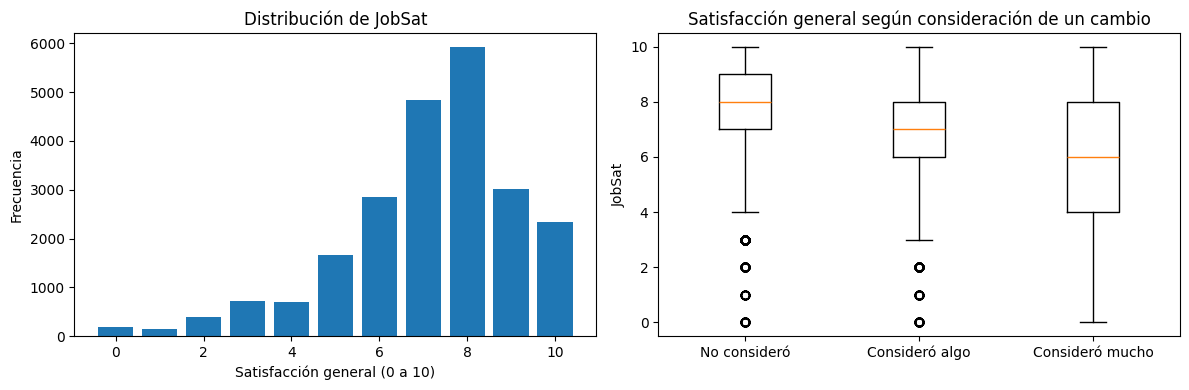

,count,mean,std,min,25%,50%,75%,max
Consideracion,,,,,,,,
No consideró,11751.0,7.78,1.68,0.0,7.0,8.0,9.0,10.0
Consideró algo,7617.0,6.80,1.81,0.0,6.0,7.0,8.0,10.0
Consideró mucho,3432.0,5.83,2.44,0.0,4.0,6.0,8.0,10.0


In [48]:
df_hc_sat = df_hc.dropna(subset=["JobSat"])
print("Observaciones con JobSat:", len(df_hc_sat))

muestra_shapiro = df_hc_sat["JobSat"].sample(5000, random_state=42)
w, p_shapiro = stats.shapiro(muestra_shapiro)
print(f"Shapiro-Wilk: W = {w:.4f}, p-valor = {p_shapiro:.2e}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].hist(df_hc_sat["JobSat"], bins=range(0, 12), align="left", rwidth=0.8)
ejes[0].set_title("Distribución de JobSat")
ejes[0].set_xlabel("Satisfacción general (0 a 10)")
ejes[0].set_ylabel("Frecuencia")

datos_por_grupo = [df_hc_sat.loc[df_hc_sat["Consideracion"] == g, "JobSat"] for g in orden_grupos]
ejes[1].boxplot(datos_por_grupo)
ejes[1].set_xticks([1, 2, 3], orden_grupos)
ejes[1].set_title("Satisfacción general según consideración de un cambio")
ejes[1].set_ylabel("JobSat")

plt.tight_layout()
plt.show()

display(df_hc_sat.groupby("Consideracion")["JobSat"].describe().reindex(orden_grupos).round(2))

El p-valor de Shapiro-Wilk es prácticamente 0, así que **rechazamos la normalidad**. Además, `JobSat` es una escala ordinal de 0 a 10, no una variable continua. Por eso no corresponde un ANOVA y usamos su alternativa no paramétrica, el **test de Kruskal-Wallis**, que compara tres o más grupos independientes a partir de los rangos de los datos.

Como la muestra es muy grande, casi cualquier diferencia mínima resulta "significativa". Por eso también calculamos el **tamaño del efecto** $\eta^2_H$ (eta cuadrado basado en el estadístico $H$), que indica qué tan grande es la diferencia:

$$\eta^2_H = \frac{H - k + 1}{n - k}$$

donde $H$ es el estadístico de Kruskal-Wallis, $k$ la cantidad de grupos y $n$ la cantidad de observaciones. Como referencia, se usan los valores 0,01 (efecto pequeño), 0,06 (moderado) y 0,14 (grande).

Si Kruskal-Wallis da significativo, comparamos los grupos de a pares con el **test de Mann-Whitney**, corrigiendo los p-valores con **Bonferroni** (multiplicándolos por la cantidad de comparaciones) para no aumentar la probabilidad de error tipo I.

In [49]:
h_sat, p_sat = stats.kruskal(*datos_por_grupo)
k = len(orden_grupos)
n_sat = len(df_hc_sat)
eta2_sat = (h_sat - k + 1) / (n_sat - k)

print(f"Kruskal-Wallis: H = {h_sat:.2f}, p-valor = {p_sat:.2e}")
print(f"Tamaño del efecto: eta²_H = {eta2_sat:.4f}")

# Comparaciones de a pares (post-hoc) con corrección de Bonferroni
pares = [("No consideró", "Consideró algo"),
         ("No consideró", "Consideró mucho"),
         ("Consideró algo", "Consideró mucho")]

resultados_pares = []
for g1, g2 in pares:
    x1 = df_hc_sat.loc[df_hc_sat["Consideracion"] == g1, "JobSat"]
    x2 = df_hc_sat.loc[df_hc_sat["Consideracion"] == g2, "JobSat"]
    u, p = stats.mannwhitneyu(x1, x2)
    resultados_pares.append({
        "Grupo 1": g1, "Grupo 2": g2,
        "Mediana 1": x1.median(), "Mediana 2": x2.median(),
        "p-valor corregido": min(p * len(pares), 1)
    })

display(pd.DataFrame(resultados_pares))

Kruskal-Wallis: H = 2879.14, p-valor = 0.00e+00
Tamaño del efecto: eta²_H = 0.1262


,Grupo 1,Grupo 2,Mediana 1,Mediana 2,p-valor corregido
0,No consideró,Consideró algo,8.0,7.0,0.000000e+00
1,No consideró,Consideró mucho,8.0,6.0,0.000000e+00
2,Consideró algo,Consideró mucho,7.0,6.0,7.181275e-96


**Resultado del paso 1:** Kruskal-Wallis da un p-valor prácticamente 0, así que **rechazamos $H_0$**: la satisfacción general es distinta según el grado de consideración de un cambio. El tamaño del efecto es $\eta^2_H \approx 0{,}126$, un efecto **moderado**, de modo que la diferencia no es solo estadística sino también relevante.

Las comparaciones de a pares muestran que **los tres grupos difieren entre sí**, y siguen un orden claro: la mediana de satisfacción es 8 en quienes no consideraron cambiar, 7 en quienes lo consideraron algo y 6 en quienes lo consideraron mucho. **Cuanto menor es la satisfacción general, mayor es la consideración de un cambio de carrera.**

#### Paso 2: importancia de cada aspecto (`JobSatPoints_*`) según la consideración de un cambio

Ahora evaluamos si la posición en la que se ubica cada aspecto cambia entre los tres grupos. Para cada uno de los 14 aspectos planteamos:

- $H_0$: la distribución de la posición del aspecto es la misma en los tres grupos.
- $H_1$: al menos un grupo ubica el aspecto en una posición distinta.

Las posiciones (1 a 15) son datos ordinales, así que nuevamente usamos **Kruskal-Wallis**. Como hacemos 14 tests, aplicamos la **corrección de Bonferroni**: un aspecto se considera significativo solo si su p-valor es menor que $0{,}05 / 14 \approx 0{,}0036$.

In [50]:
df_hc_asp = df_hc.dropna(subset=cols_aspectos)
n_asp = len(df_hc_asp)
alfa_bonferroni = 0.05 / len(cols_aspectos)
print("Observaciones con el ranking completo:", n_asp)
print(f"Nivel de significancia corregido (Bonferroni): {alfa_bonferroni:.4f}")

resultados_asp = []
for col in cols_aspectos:
    grupos = [df_hc_asp.loc[df_hc_asp["Consideracion"] == g, col] for g in orden_grupos]
    h, p = stats.kruskal(*grupos)
    resultados_asp.append({
        "Aspecto": aspectos_hc[col],
        "Posición media - No consideró": grupos[0].mean(),
        "Posición media - Consideró algo": grupos[1].mean(),
        "Posición media - Consideró mucho": grupos[2].mean(),
        "H": h,
        "p-valor": p,
        "Significativo (Bonferroni)": p < alfa_bonferroni,
        "eta²_H": (h - k + 1) / (n_asp - k)
    })

tabla_asp = pd.DataFrame(resultados_asp).sort_values("eta²_H", ascending=False)
display(tabla_asp.round(4))

Observaciones con el ranking completo: 21409
Nivel de significancia corregido (Bonferroni): 0.0036


,Aspecto,Posición media - No consideró,Posición media - Consideró algo,Posición media - Consideró mucho,H,p-valor,Significativo (Bonferroni),eta²_H
3,Mentores expertos,9.7150,9.5518,9.1747,54.8002,0.0000,True,0.0025
4,Orientar a otros,9.9102,9.7808,9.4498,40.8221,0.0000,True,0.0018
1,Autonomía y confianza,5.1107,5.1646,5.5180,31.6916,0.0000,True,0.0014
8,Problemas complejos,6.6459,6.9526,6.7966,28.4967,0.0000,True,0.0012
10,Remuneración y beneficios,5.7561,5.5239,5.7262,15.1493,0.0005,True,0.0006
0,Control sobre la calidad,6.7578,6.9261,6.9586,12.3637,0.0021,True,0.0005
7,Estabilidad y crecimiento,7.2856,7.1950,7.4609,9.3801,0.0092,False,0.0003
6,Resolver problemas reales,5.8607,5.9164,6.0067,3.2957,0.1925,False,0.0001
2,Colaboración del equipo,7.4704,7.4284,7.5508,2.2643,0.3223,False,0.0000
13,Relación con el gerente,7.7941,7.8487,7.9056,2.2104,0.3311,False,0.0000


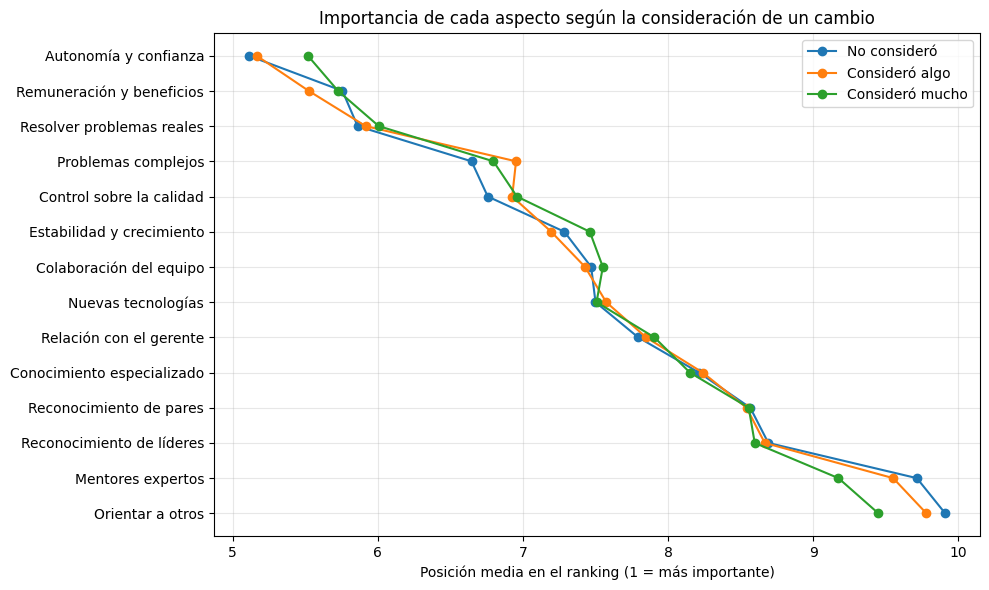

In [51]:
# Posición media de cada aspecto en cada grupo (1 = más importante)
medias_asp = df_hc_asp.groupby("Consideracion")[cols_aspectos].mean().reindex(orden_grupos)
medias_asp.columns = [aspectos_hc[c] for c in cols_aspectos]
orden_aspectos = medias_asp.mean().sort_values().index

plt.figure(figsize=(10, 6))
for grupo in orden_grupos:
    plt.plot(medias_asp.loc[grupo, orden_aspectos], orden_aspectos, marker="o", label=grupo)
plt.gca().invert_yaxis()
plt.xlabel("Posición media en el ranking (1 = más importante)")
plt.title("Importancia de cada aspecto según la consideración de un cambio")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Resultado del paso 2:** 6 de los 14 aspectos dan significativos después de la corrección de Bonferroni (mentores expertos, orientar a otros, autonomía y confianza, problemas complejos, remuneración y control sobre la calidad). Sin embargo, el tamaño del efecto es **despreciable** en todos los casos: el mayor $\eta^2_H$ es 0,0025, muy por debajo de 0,01 (efecto pequeño). Las diferencias en la posición media son de menos de un lugar del ranking.

El gráfico lo confirma: las tres líneas prácticamente se superponen. Los tres grupos ordenan los aspectos casi de la misma manera, con la autonomía, la remuneración y resolver problemas reales en los primeros lugares. La significancia de algunos tests se explica por el gran tamaño de la muestra y no por una diferencia relevante.

#### Paso 3: análisis multivariado con regresión logística

Los pasos anteriores analizan cada variable por separado. Para evaluar **todas las variables en conjunto**, como pide la hipótesis, usamos una **regresión logística**, que predice una variable categórica binaria a partir de varias variables explicativas.

- **Variable a predecir:** si la persona consideró un cambio (1 = consideró algo o mucho; 0 = no consideró).
- **Variables explicativas:** los 14 rankings de aspectos y la satisfacción general `JobSat`.

Entrenamos tres modelos para ver qué aporta cada grupo de variables:
1. Solo los 14 aspectos.
2. Solo la satisfacción general.
3. Todas las variables juntas.

Dividimos los datos en 70 % para entrenamiento y 30 % para prueba, y estandarizamos las variables para que sus coeficientes sean comparables. Como cada persona ordena los aspectos, las variables de ranking dependen entre sí (si una sube, otra baja); la regresión logística de scikit-learn incluye por defecto una regularización que tolera esta dependencia.

Evaluamos los modelos con la **exactitud (accuracy)** en el conjunto de prueba y la comparamos con un **modelo trivial** que predice siempre la clase más frecuente. Si un modelo no supera al trivial, esas variables no ayudan a distinguir quién consideró un cambio.

In [52]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df_hc_modelo = df_hc.dropna(subset=cols_aspectos + ["JobSat"]).copy()
df_hc_modelo["ConsideroCambio"] = (df_hc_modelo["Consideracion"] != "No consideró").astype(int)
print("Observaciones para el modelo:", len(df_hc_modelo))
print(f"Proporción que consideró un cambio: {df_hc_modelo['ConsideroCambio'].mean():.3f}")

modelos_hc = {
    "Solo aspectos": cols_aspectos,
    "Solo satisfacción general": ["JobSat"],
    "Aspectos + satisfacción general": cols_aspectos + ["JobSat"]
}

resultados_modelos = []
for nombre, variables in modelos_hc.items():
    X_train, X_test, y_train, y_test = train_test_split(
        df_hc_modelo[variables], df_hc_modelo["ConsideroCambio"],
        test_size=0.3, random_state=42, stratify=df_hc_modelo["ConsideroCambio"]
    )
    escalador = StandardScaler().fit(X_train)
    modelo = LogisticRegression(max_iter=1000).fit(escalador.transform(X_train), y_train)
    y_pred = modelo.predict(escalador.transform(X_test))

    resultados_modelos.append({"Modelo": nombre, "Accuracy": accuracy_score(y_test, y_pred)})

    if nombre == "Aspectos + satisfacción general":
        modelo_completo, y_test_completo, y_pred_completo = modelo, y_test, y_pred
        variables_completo = variables

accuracy_trivial = max(y_test.mean(), 1 - y_test.mean())
resultados_modelos.append({"Modelo": "Trivial (clase más frecuente)", "Accuracy": accuracy_trivial})
display(pd.DataFrame(resultados_modelos).round(4))

Observaciones para el modelo: 20643
Proporción que consideró un cambio: 0.484


,Modelo,Accuracy
0,Solo aspectos,0.5319
1,Solo satisfacción general,0.6482
2,Aspectos + satisfacción general,0.6520
3,Trivial (clase más frecuente),0.5166


Matriz de confusión (filas = clase real, columnas = clase predicha):


,Pred: no consideró,Pred: consideró
Real: no consideró,2403,796
Real: consideró,1359,1635


              precision    recall  f1-score   support

No consideró       0.64      0.75      0.69      3199
   Consideró       0.67      0.55      0.60      2994

    accuracy                           0.65      6193
   macro avg       0.66      0.65      0.65      6193
weighted avg       0.66      0.65      0.65      6193



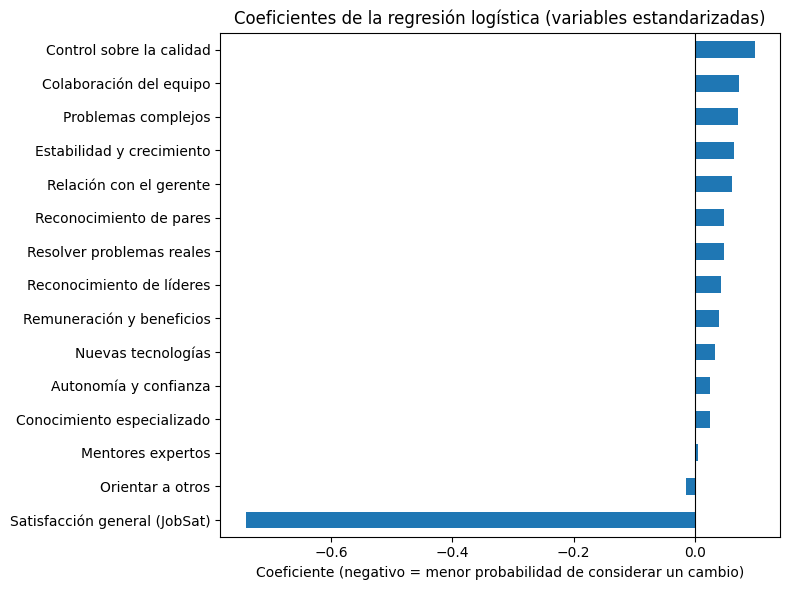

In [53]:
# Detalle del modelo con todas las variables
print("Matriz de confusión (filas = clase real, columnas = clase predicha):")
display(pd.DataFrame(confusion_matrix(y_test_completo, y_pred_completo),
                     index=["Real: no consideró", "Real: consideró"],
                     columns=["Pred: no consideró", "Pred: consideró"]))

print(classification_report(y_test_completo, y_pred_completo,
                            target_names=["No consideró", "Consideró"]))

nombres_variables = [aspectos_hc.get(v, "Satisfacción general (JobSat)") for v in variables_completo]
coeficientes = pd.Series(modelo_completo.coef_[0], index=nombres_variables).sort_values()

plt.figure(figsize=(8, 6))
coeficientes.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Coeficientes de la regresión logística (variables estandarizadas)")
plt.xlabel("Coeficiente (negativo = menor probabilidad de considerar un cambio)")
plt.tight_layout()
plt.show()

**Resultado del paso 3:**

- El modelo con **solo los aspectos** alcanza una exactitud de **53,2 %**, apenas 1,5 puntos más que el modelo trivial (51,7 %). Es decir, **conocer cómo una persona ordena los aspectos de su trabajo casi no ayuda a predecir si consideró un cambio**.
- El modelo con **solo la satisfacción general** sube la exactitud a **64,8 %**, unos 13 puntos por encima del modelo trivial.
- El modelo con **todas las variables** obtiene **65,2 %**: agregar los aspectos a la satisfacción general suma menos de medio punto.

Los coeficientes lo confirman: `JobSat` tiene un coeficiente de **−0,74**, mucho mayor en valor absoluto que el de cualquier aspecto (todos menores a 0,1). El signo negativo indica que a mayor satisfacción general, menor es la probabilidad de haber considerado un cambio.

#### Conclusión de la hipótesis c)

La hipótesis se **confirma parcialmente**:

- **Sí** existe una relación clara entre el **nivel de satisfacción general** con el trabajo y la consideración de un cambio de carrera. Quienes están menos satisfechos consideran más el cambio (medianas de 8, 7 y 6), con un tamaño de efecto moderado. Es la variable que explica casi toda la capacidad predictiva del modelo multivariado.
- **No** encontramos una relación relevante entre la **importancia que se le da a cada aspecto** del trabajo y la consideración de un cambio. Aunque algunos tests resultan significativos por el tamaño de la muestra, los efectos son despreciables y los aspectos casi no mejoran la predicción.

En otras palabras: lo que se relaciona con querer cambiar de carrera es **cuán satisfecha está la persona**, no **qué aspectos del trabajo valora más**. Como limitación, la encuesta no mide la satisfacción con cada aspecto por separado, sino su importancia relativa, por lo que no podemos saber si alguien está insatisfecho con un aspecto puntual (por ejemplo, la remuneración).